# モデル間の比較

宇宙線電離率 $\zeta_{\rm CR}$ の異なるモデルを 1 枚の図で比較するノートブック。

- データの場所、半径の範囲、物理定数、ラベル、文字サイズ、ギャップの判定条件は `thesis_common.ipynb` で指定する。
- 比較するモデルとその色は次のセルの `RUN_COLORS` で指定する。


In [1]:
# 共通設定を読み込む (範囲や文字サイズは thesis_common.ipynb で変更する)
import json

def run_nb(path):
    # 別のノートブックのコードセルをこのノートブックの変数空間で実行する
    for c in json.load(open(path))["cells"]:
        if c["cell_type"] == "code":
            exec("".join(c["source"]), globals())

run_nb("thesis_common.ipynb")
plt.rcParams.update(PLOT_STYLE)

G_cgs = G
YEAR = yr
SIGMA_SB = sigma_SB
R_CUT_AU = 100.0         # cut_off (beta3/beta4/beta5 の input ファイルで共通)

# gas file (out<N>_gas) column indices -- see disk_anim_common.py / thesis.ipynb
GAS_R, SIGMAG, SIGMAD_TOT, SIGMAD_VAPOR = 0, 1, 2, 3
VG_R, VG_PHI, VG_WIND = 4, 5, 6
DSIGMAGDT_W = 11
TEMP = 12
ALPHA_GI, ALPHA_PHIZ, ALPHA_TOT, ETA_P = 16, 17, 18, 19
ALPHA_WIND = 17   # alpha_phiz : energy.cpp CalcWindHeating() の F_wind が使う値 (alpha_DW_ は列24でトルク用)

# B file (out<N>_B) column indices
MAG_R, ALPHA_MRI, B_FIELD, ETA_O, ETA_A, BETA_DISK = 0, 1, 2, 3, 4, 5

In [ ]:
# 比較するモデルと色
RUN_COLORS = {
    "/test1e18": "tab:blue",
    "/test1e17": "tab:green",
    "/test1e16": "tab:orange",
    "/test1e15": "tab:red",
}
RUNS = [{'key': m.lstrip('/'), 'label': model_names[m], 'color': color,
         'dir': BASE_DIR + m, 'B_dir': BASE_DIR + m + '_B'} for m, color in RUN_COLORS.items()]

def b_dir(run):
    return run['B_dir'] or run['dir']

def gas_path(run, t):
    return os.path.join(run['dir'], f'out{t}_gas')

def dust_path(run, t):
    return os.path.join(run['dir'], f'out{t}')

def b_path(run, t):
    return os.path.join(b_dir(run), f'out{t}_B')

def load_gas(run, t):
    """Returns the (nr, 25) gas snapshot array for run at time t (int/str year label)."""
    return np.loadtxt(gas_path(run, t))

def load_B(run, t):
    """Returns the (nr, 6) magnetic-field snapshot array for run at time t."""
    return np.loadtxt(b_path(run, t))

def load_dust(run, t):
    """Returns (r_cm, a_bins, sigmad) with sigmad shape (nbin, nr)."""
    path = dust_path(run, t)
    with open(path) as f:
        f.readline(); f.readline()
        a_bins = np.array(f.readline().split(), dtype=float)
    data = np.loadtxt(path, skiprows=5).T
    return data[0], a_bins, data[1:]

def available_times(run):
    """Sorted list of int year labels that have an out<N>_gas file."""
    import re
    times = []
    for name in os.listdir(run['dir']):
        m = re.match(r'^out(\d+)_gas$', name)
        if m:
            times.append(int(m.group(1)))
    return sorted(times)

for run in RUNS:
    ts = available_times(run)
    print(f"{run['key']:6s}: {len(ts)} snapshots, "
          f"{ts[0] if ts else '-'} .. {ts[-1] if ts else '-'} yr")


beta4_zeta1e18: 290 snapshots, 0 .. 100000 yr
beta4 : 380 snapshots, 0 .. 1000000 yr
beta4_zeta1e16: 330 snapshots, 0 .. 500000 yr
beta4_zeta1e15: 290 snapshots, 0 .. 100000 yr


In [3]:


def deriv3(f, rr):
    """Non-uniform 3-point derivative (thesis.ipynb と同じ)."""
    d = np.zeros_like(f)
    s = rr[1:-1] - rr[:-2]
    t = rr[2:] - rr[1:-1]
    d[1:-1] = (s**2*f[2:] + (t**2 - s**2)*f[1:-1] - t**2*f[:-2]) / (s*t*(s+t))
    d[0] = d[1]
    d[-1] = d[-2]
    return d

def flux_div(r, sigmag, v):
    """-(1/r) d/dr(r*sigmag*v) -- radial continuity-equation flux divergence."""
    return -deriv3(r*sigmag*v, r) / r

def dsigmagdt_total(run, t):
    """dSigma_g/dt_total = -(1/r) d/dr(r*Sigma_g*vg_r) - dsigmagdt_w (thesis.ipynb cell 70 と同じ式,
    vg_r/dsigmagdt_w は成分分解に依存しないので独立に厳密)."""
    gas = load_gas(run, t)
    r_cm   = gas[:, GAS_R]
    sigmag = gas[:, SIGMAG]
    vg_r_s        = gas[:, VG_R]
    dsigmagdt_w_s = gas[:, DSIGMAGDT_W]
    return flux_div(r_cm, sigmag, vg_r_s) - dsigmagdt_w_s

def timescale_total(run, t):
    """R = Sigma_g / (dSigma_g/dt_total)  [yr] -- 特性タイムスケール(符号込み、
    thesis.ipynb cell 73 と同じ定義)。dsdt_total ~ 0 付近で発散するので非有限値は NaN。"""
    gas = load_gas(run, t)
    sigmag = gas[:, SIGMAG]
    dsdt = dsigmagdt_total(run, t)
    with np.errstate(divide='ignore', invalid='ignore'):
        R = sigmag / dsdt / YEAR
    R[~np.isfinite(R)] = np.nan
    return R

def mean_dust_size(dradius, sigmad):
    """Sigma_d 重み付き平均ダスト半径 [cm] (disk_anim_common.mean_dust_size と同じ定義)."""
    sig_tot = sigmad.sum(axis=0)
    with np.errstate(invalid='ignore', divide='ignore'):
        amean = (dradius[:, None] * sigmad).sum(axis=0) / sig_tot
    amean[sig_tot <= 0] = np.nan
    return amean

def plot_signed(ax, r_AU, v, color, linewidth=1.6, label=None):
    """色=物理量(run)固定、線種=符号(正=実線/負=破線)、値は絶対値で描く(thesis.ipynb cell 70 と同じ house style)."""
    pos = np.where(v >= 0, v, np.nan)
    neg = np.where(v < 0, -v, np.nan)
    ax.plot(r_AU, pos, color=color, linewidth=linewidth, linestyle='-',  label=label)
    ax.plot(r_AU, neg, color=color, linewidth=linewidth, linestyle='--')

def time_label_latex(t):
    """年数を '$3.0 \\times 10^{5}\\ \\rm{yr}$' のような表記にする(thesis.ipynb の time_label_latex と同じ)."""
    y = float(t)
    if y == 0:
        return r'$0\ \rm{yr}$'
    exp = int(np.floor(np.log10(y)))
    mant = y / 10**exp
    return r'$%.1f \times 10^{%d}\ \rm{yr}$' % (mant, exp)

def reconstruct_omega(run, t, star_mass_msun=1.0):
    """Omega_K(r) = sqrt(G*M_in/r^3), M_in = star_mass + 累積 pi*Sigma_g*r_vol
    (dust_disk.cpp:1206-1212 と同じ式; 動径グリッドが log であることを仮定)."""
    gas = load_gas(run, t)
    r_cm, sigmag = gas[:, GAS_R], gas[:, SIGMAG]
    q = r_cm[1:] / r_cm[:-1]
    if not np.allclose(q, q[0], rtol=1e-6):
        print(f'WARNING: {run["key"]} の動径グリッドは log ではない可能性があります')
    r_lo, r_hi = r_cm / np.sqrt(q[0]), r_cm * np.sqrt(q[0])
    dM = np.pi * sigmag * (r_hi**2 - r_lo**2)
    dM[0] = np.pi * sigmag[0] * r_hi[0]**2
    M_in = star_mass_msun * Msolar + np.cumsum(dM)
    return np.sqrt(G_cgs * M_in / r_cm**3)

def elsasser_numbers(run, t):
    """Lambda_A = V_A^2/(etaA*Omega_K), Lambda_O = V_A^2/(etaO*Omega_K)
    (magnetic_field1D.cpp:534-535, alpha.cpp:926-928 と同じ定義)。
    V_A = B/sqrt(4*pi*rho_mid), rho_mid = Sigma_g/(sqrt(2*pi)*Hg), Hg = cs/Omega_K."""
    gas = load_gas(run, t)
    sigmag, T = gas[:, SIGMAG], gas[:, TEMP]
    B = load_B(run, t)
    Bfield, etaO, etaA = B[:, B_FIELD], B[:, ETA_O], B[:, ETA_A]
    Omega = reconstruct_omega(run, t)
    cs = np.sqrt(kB * T / (mu * mH))
    Hg = cs / Omega
    rho_mid = sigmag / (np.sqrt(2.0*np.pi) * Hg)
    vA2 = Bfield**2 / (4.0*np.pi*rho_mid)
    Lam_A = vA2 / (etaA * Omega)
    Lam_O = vA2 / (etaO * Omega)
    return Lam_A, Lam_O

def irr_temperature(r_AU):
    """T_irr(r) = max(20*(r/r_cut)^-0.45, 10)  [K] -- dust_disk.cpp:1325-1333 の
    MMSN初期プロファイルで、Initialization() の1回だけ T_irr に複写されて以降
    二度と更新されない(= 時間に依存しない外部照射温度として扱われている)。"""
    T = 20.0 * (r_AU / R_CUT_AU) ** (-0.45)
    return np.maximum(T, 10.0)

def rosseland_opacity(T_mid):
    """KR(T) -- energy.cpp RosselandOpacity() と同じ式(Kunitomo et al. 2020 eq.9)."""
    KR = 2.25 * (1.0 - np.tanh((T_mid - 1.5e3) / 1.5e2))
    KR *= np.minimum(1.0, (T_mid / 1.5e2) ** 2)
    return KR

def heating_rates(run, t):
    """F_vis = 2.25*sqrt(2*pi)*rho_mid*cs^3*alpha_MRI (viscous), F_wind =
    0.5*r*Omega_K*alpha_phiz*rho_mid*cs^2 (wind torque), F_irr = C*T_irr^4 with
    C = 8*tauR*sigma_SB/(3*tauR^2+1), tauR = KR(T_mid)*Sigma_g (irradiation,
    re-processed through the local optical depth) -- energy.cpp
    CalcViscousHeating()/CalcWindHeating()/Calculate_Dt() と同じ式(いずれも
    中間面 T=T_mid 版)。T_irr 自体は時間に依存しない(irr_temperature 参照)が、
    tauR は Sigma_g(t)/T_mid(t) 経由でわずかに時間発展する。
    rho_mid, cs, Omega は elsasser_numbers と同じ再構成。"""
    gas = load_gas(run, t)
    r_cm, sigmag, T = gas[:, GAS_R], gas[:, SIGMAG], gas[:, TEMP]
    alpha_wind = gas[:, ALPHA_WIND]
    B = load_B(run, t)
    alpha_MRI = B[:, ALPHA_MRI]
    Omega = reconstruct_omega(run, t)
    cs = np.sqrt(kB * T / (mu * mH))
    Hg = cs / Omega
    rho_mid = sigmag / (np.sqrt(2.0*np.pi) * Hg)
    F_vis  = 2.25 * np.sqrt(2.0*np.pi) * rho_mid * cs**3 * alpha_MRI
    F_wind = 0.5 * r_cm * Omega * alpha_wind * rho_mid * cs**2

    tauR = rosseland_opacity(T) * sigmag
    C = 8.0 * tauR * SIGMA_SB / (3.0 * tauR**2 + 1.0)
    T_irr4 = irr_temperature(r_cm / AU) ** 4
    F_irr = C * T_irr4

    return F_vis, F_wind, F_irr

## 第1パネル: 指定時刻での Sigma_g/Sigma_d,tot, B, T, alpha_phiz 比較 (2x2)

モデルごとに色分け。Sigma_g(実線) と Sigma_d,tot(破線) は同じ図に重ねる。
`time_label` は全モデルに出力がある時刻にする。


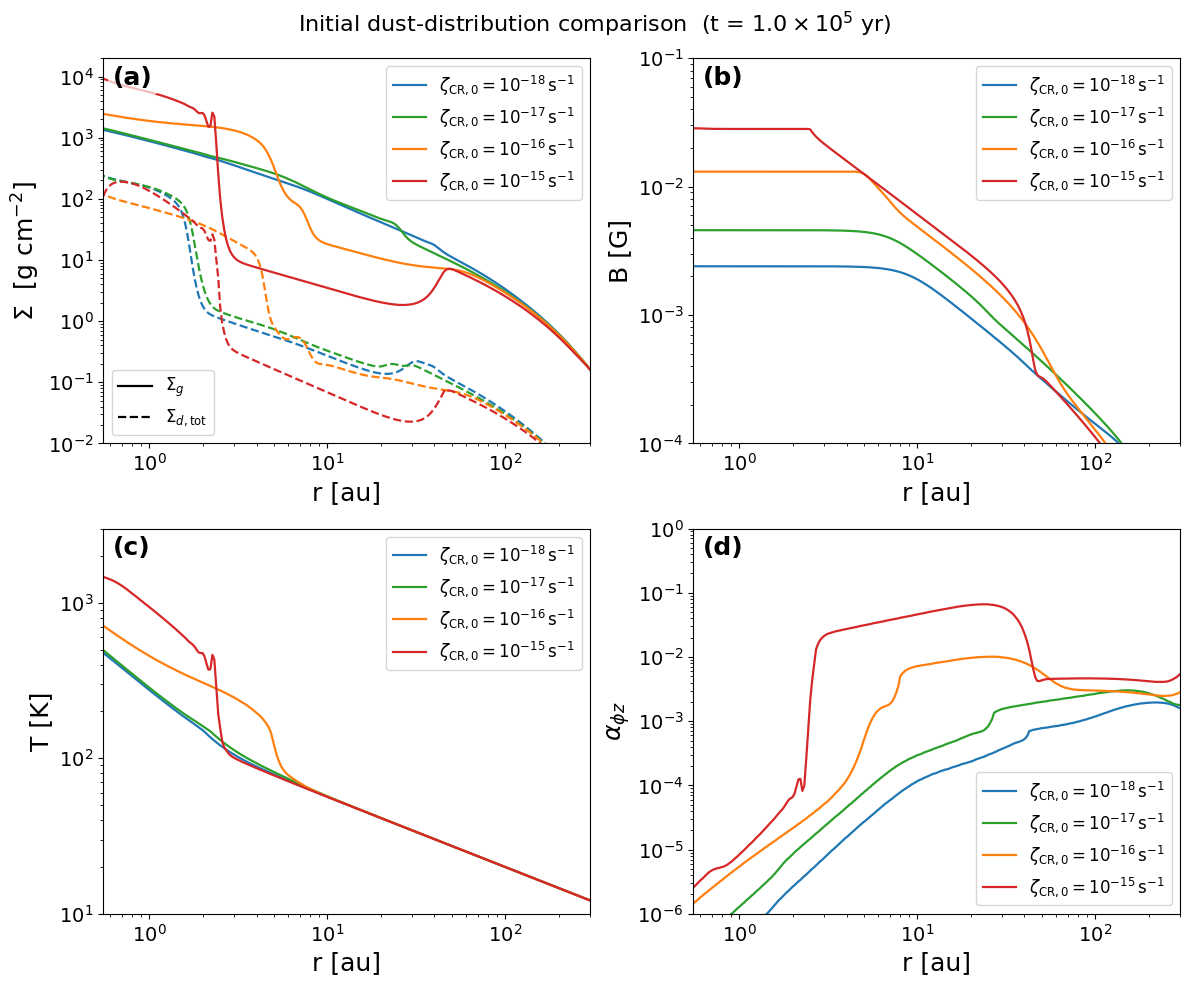

In [4]:
time_label = '100000'   # yr -- 全モデルに出力がある時刻にする

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
ax_sigma, ax_B, ax_T, ax_alpha = axes.flat

for run in RUNS:
    gas = load_gas(run, time_label)
    r_AU = gas[:, GAS_R] / AU
    color, label = run['color'], run['label']

    ax_sigma.plot(r_AU, gas[:, SIGMAG],     color=color, linewidth=1.6, linestyle='-',  label=label)
    ax_sigma.plot(r_AU, gas[:, SIGMAD_TOT], color=color, linewidth=1.6, linestyle='--')

    B = load_B(run, time_label)
    ax_B.plot(r_AU, B[:, B_FIELD], color=color, linewidth=1.6, label=label)

    ax_T.plot(r_AU, gas[:, TEMP], color=color, linewidth=1.6, label=label)

    ax_alpha.plot(r_AU, gas[:, ALPHA_PHIZ], color=color, linewidth=1.6, label=label)

ax_sigma.set_xscale('log'); ax_sigma.set_yscale('log')
ax_sigma.set_xlim(r_min, r_max)
ax_sigma.set_ylim(1.0e-2, 2.0e4)
ax_sigma.set_xlabel('r [au]'); ax_sigma.set_ylabel(r'$\Sigma$  [g cm$^{-2}$]')
# ax_sigma.set_title(r'$\Sigma_g$ (solid) / $\Sigma_{d,\rm tot}$ (dashed)')
# 凡例を2つに分ける: 色 = run (zeta), 線種 = Sigma_g / Sigma_d,tot
leg_run = ax_sigma.legend(handles=[Line2D([0], [0], color=run['color'], linewidth=1.6, label=run['label']) for run in RUNS],
                          loc='upper right')
ax_sigma.add_artist(leg_run)   # 2つ目の legend() で消えないように残す
ax_sigma.legend(handles=[Line2D([0], [0], color='black', linewidth=1.6, linestyle='-',  label=r'$\Sigma_g$'),
                         Line2D([0], [0], color='black', linewidth=1.6, linestyle='--', label=r'$\Sigma_{d,\rm tot}$')],
                loc='lower left')

ax_B.set_xscale('log'); ax_B.set_yscale('log')
ax_B.set_xlim(r_min, r_max)
ax_B.set_ylim(1.0e-4, 1.0e-1)
ax_B.set_xlabel('r [au]'); ax_B.set_ylabel('B [G]')
# ax_B.set_title('Magnetic field')
ax_B.legend(loc='best')

ax_T.set_xscale('log'); ax_T.set_yscale('log')
ax_T.set_xlim(r_min, r_max)
ax_T.set_ylim(1.0e1, 3.0e3)
ax_T.set_xlabel('r [au]'); ax_T.set_ylabel('T [K]')
# ax_T.set_title('Temperature')
ax_T.legend(loc='best')

ax_alpha.set_xscale('log'); ax_alpha.set_yscale('log')
ax_alpha.set_xlim(r_min, r_max)
ax_alpha.set_ylim(1.0e-6, 1.0e0)
ax_alpha.set_xlabel('r [au]'); ax_alpha.set_ylabel(r'$\alpha_{\phi z}$')
# ax_alpha.set_title(r'$\alpha_{\phi z}$ ')
ax_alpha.legend(loc='best')

fig.suptitle(f'Initial dust-distribution comparison  (t = {time_label_latex(time_label)})')
plt.tight_layout()
plt.show()


## 第2パネル: R = Sigma_g/(dSigma_g/dt), vg_r, 平均ダストサイズ, alpha_MRI 比較 (2x2)

同じ `time_label`, モデルごとに色分け。

- R = Sigma_g/(dSigma_g/dt_total): 総ガス面密度進化の特性タイムスケール(符号込み、thesis.ipynb cell 73 と同じ定義)。
  dSigma_g/dt_total は成分分解に依存せず厳密。色=run固定、線種=符号(正=実線・成長中/負=破線・減少中、絶対値でlogスケール)。
- vg_r: ガウシアンフィルター適用、y軸 symlog(thesis.ipynb cell 61 と同じ)。
- 平均ダストサイズ ā_d: Sigma_d 重み付き平均。
- alpha_MRI: B ファイル col1。


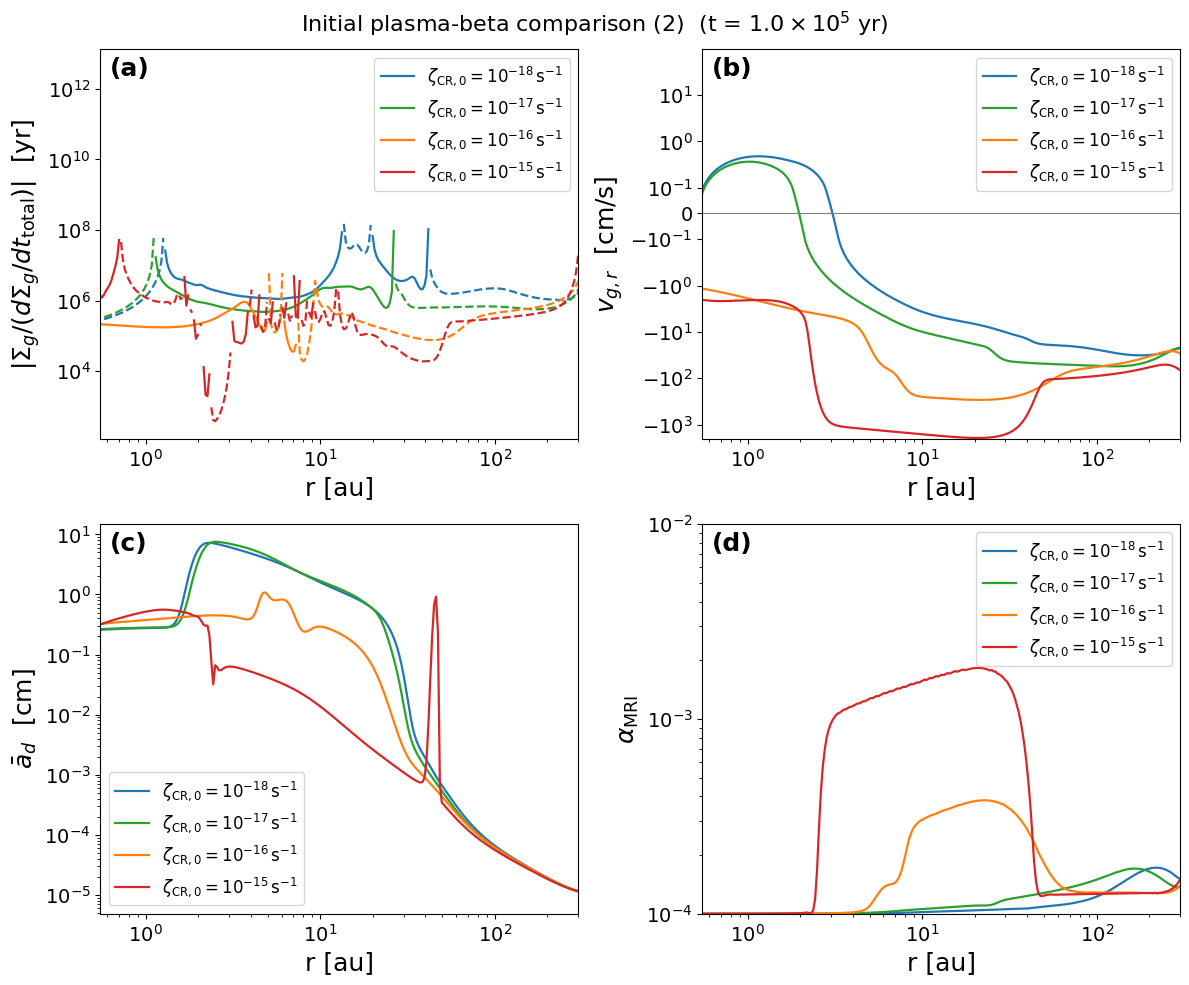

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
ax_R, ax_vgr, ax_ad, ax_aMRI = axes.flat

for run in RUNS:
    gas = load_gas(run, time_label)
    r_AU = gas[:, GAS_R] / AU
    color, label = run['color'], run['label']

    R = timescale_total(run, time_label)
    plot_signed(ax_R, r_AU, R, color, label=label)

    vg_r_s = gas[:, VG_R]
    ax_vgr.plot(r_AU, vg_r_s, color=color, linewidth=1.6, label=label)

    r_cm, a_bins, sigmad = load_dust(run, time_label)
    ad = mean_dust_size(a_bins, sigmad)
    ax_ad.plot(r_AU, ad, color=color, linewidth=1.6, label=label)

    B = load_B(run, time_label)
    ax_aMRI.plot(r_AU, B[:, ALPHA_MRI], color=color, linewidth=1.6, label=label)

ax_R.set_xscale('log'); ax_R.set_yscale('log')
ax_R.set_xlim(r_min, r_max)
ax_R.set_xlabel('r [au]'); ax_R.set_ylabel(r'$|\Sigma_g/(d\Sigma_g/dt_{\rm total})|  $  [yr]')
# ax_R.set_title(r'$R = \Sigma_g/(d\Sigma_g/dt_{\rm total})$ (solid: $\geq 0$, dashed: $<0$)')
ax_R.legend(loc='best')

ax_vgr.set_xscale('log'); ax_vgr.set_yscale('symlog', linthresh=1.0e-1, linscale=0.5)
ax_vgr.set_xlim(r_min, r_max)
ax_vgr.set_xlabel('r [au]'); ax_vgr.set_ylabel(r'$v_{g,r}$  [cm/s]')
ax_vgr.axhline(0, color='gray', linewidth=0.8)
# ax_vgr.set_title('Gas radial velocity')
ax_vgr.legend(loc='best')

ax_ad.set_xscale('log'); ax_ad.set_yscale('log')
ax_ad.set_xlim(r_min, r_max)
ax_ad.set_xlabel('r [au]'); ax_ad.set_ylabel(r'$\bar{a}_d$  [cm]')
# ax_ad.set_title(r'Mean dust size')
ax_ad.legend(loc='best')

ax_aMRI.set_xscale('log'); ax_aMRI.set_yscale('log')
ax_aMRI.set_xlim(r_min, r_max)
ax_aMRI.set_ylim(1.0e-4, 1.0e-2)
ax_aMRI.set_xlabel('r [au]'); ax_aMRI.set_ylabel(r'$\alpha_{\rm MRI}$')
# ax_aMRI.set_title('MRI turbulence alpha')
ax_aMRI.legend(loc='best')

fig.suptitle(f'Initial plasma-beta comparison (2)  (t = {time_label_latex(time_label)})')
plt.tight_layout()
plt.show()


## 3 時刻の動径分布のミニマップ: 面密度 (ガス, ダスト), 磁場, 温度, alpha_MRI, alpha_phiz, eta_O, eta_A, beta, 2 pi r B_z

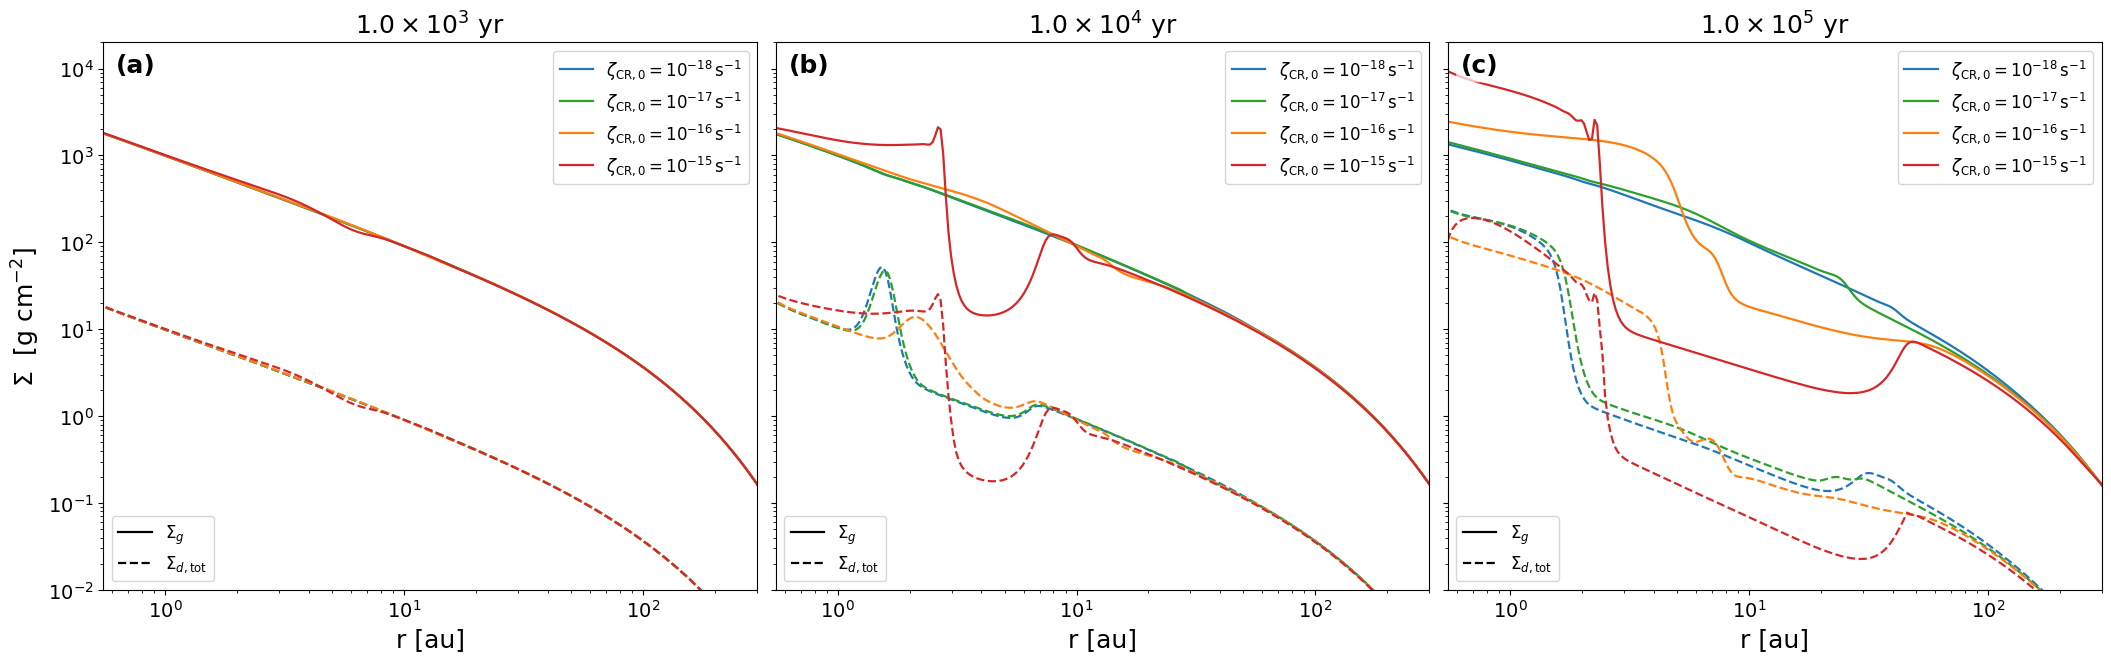

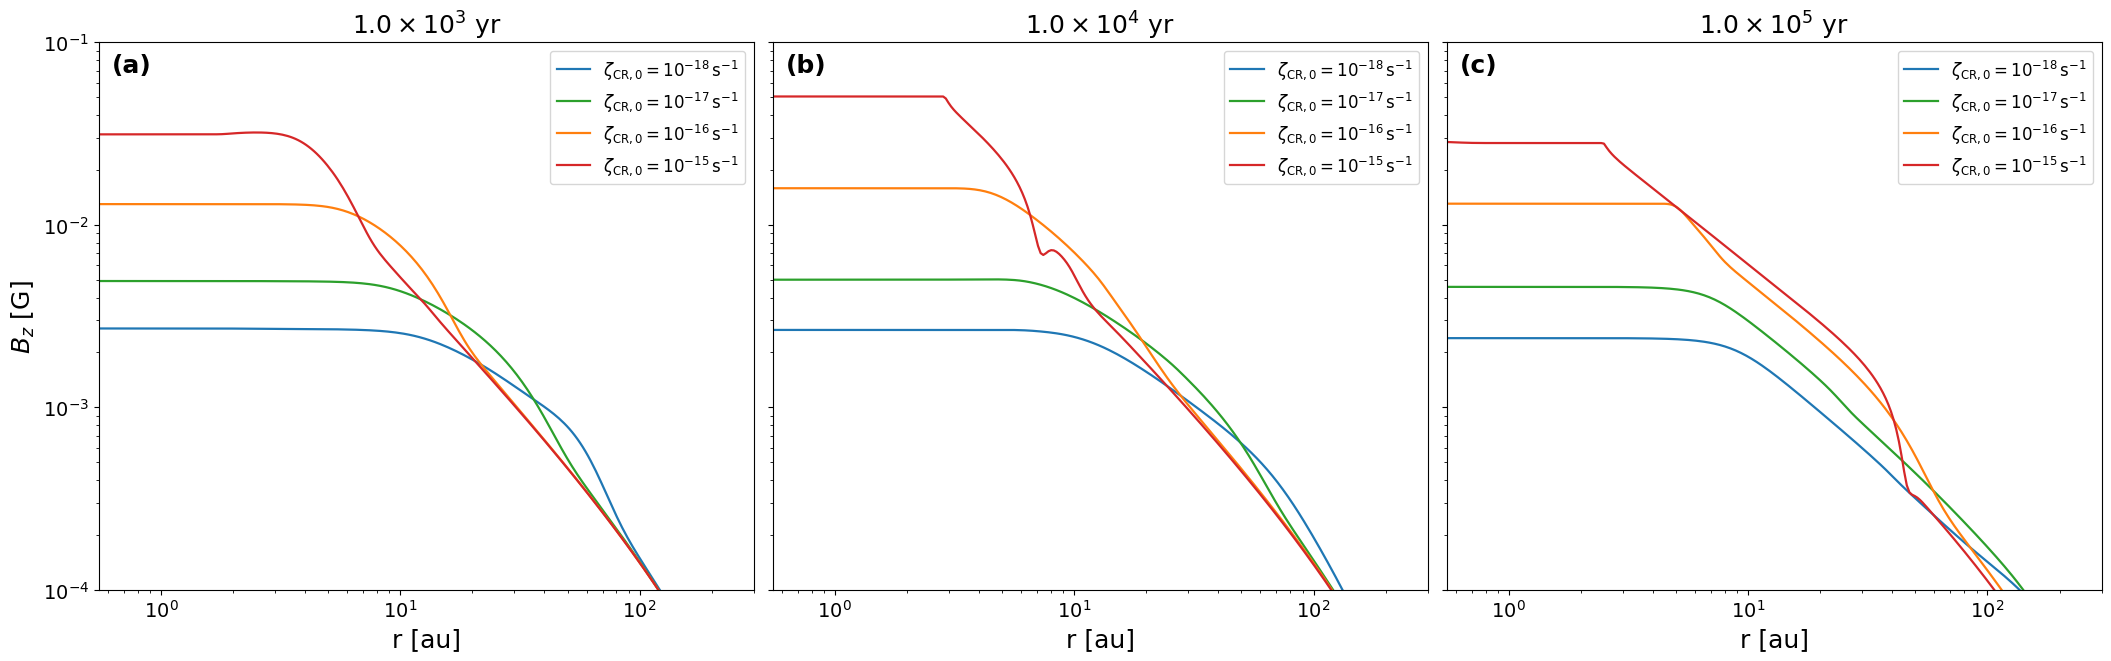

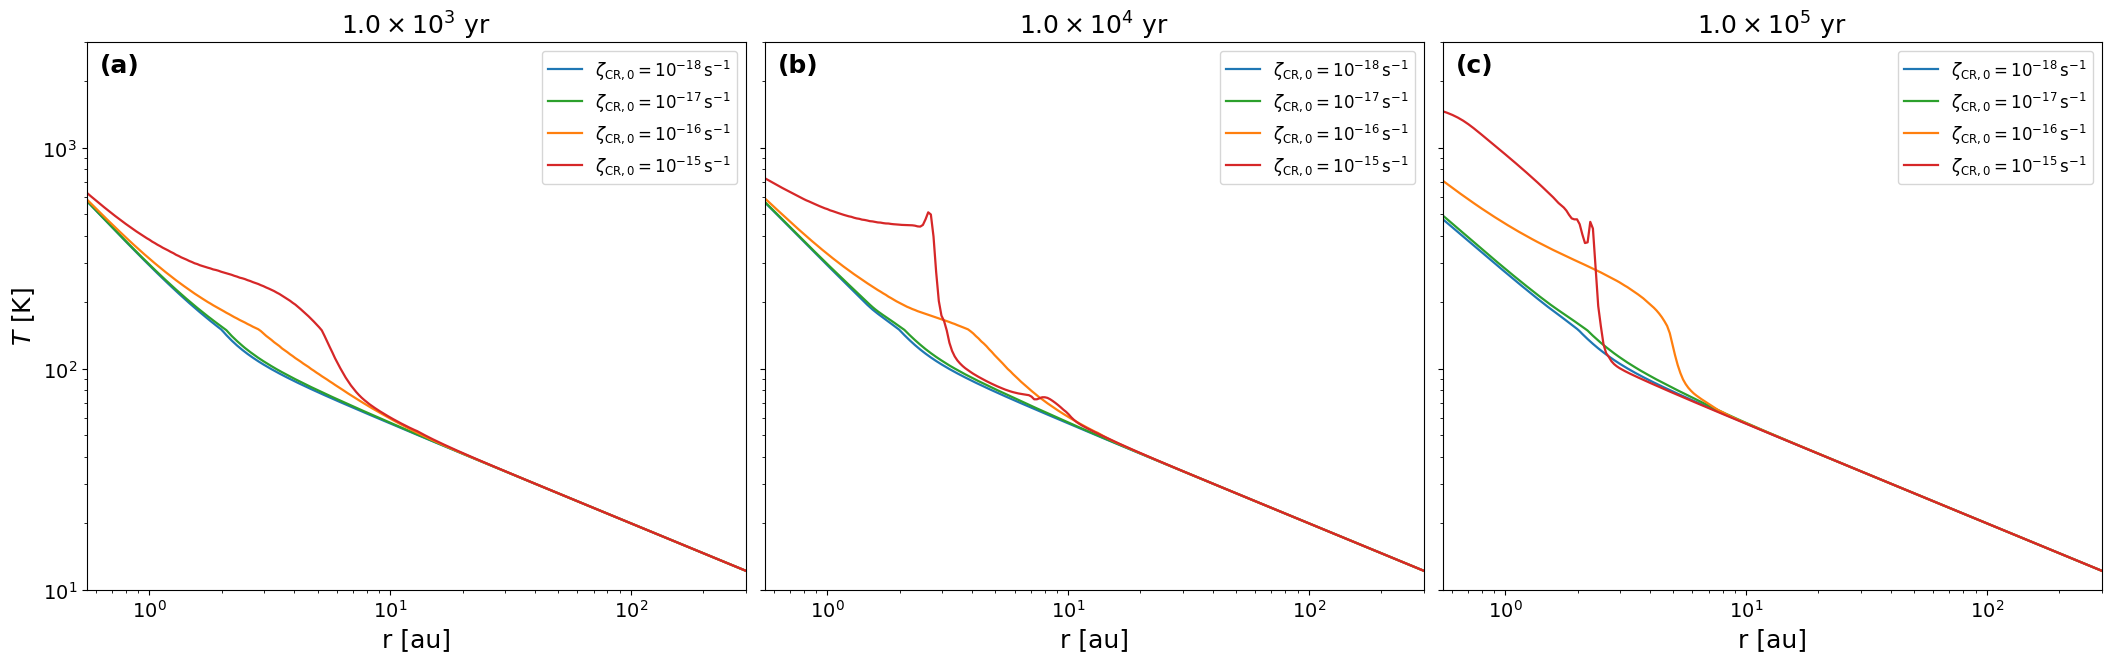

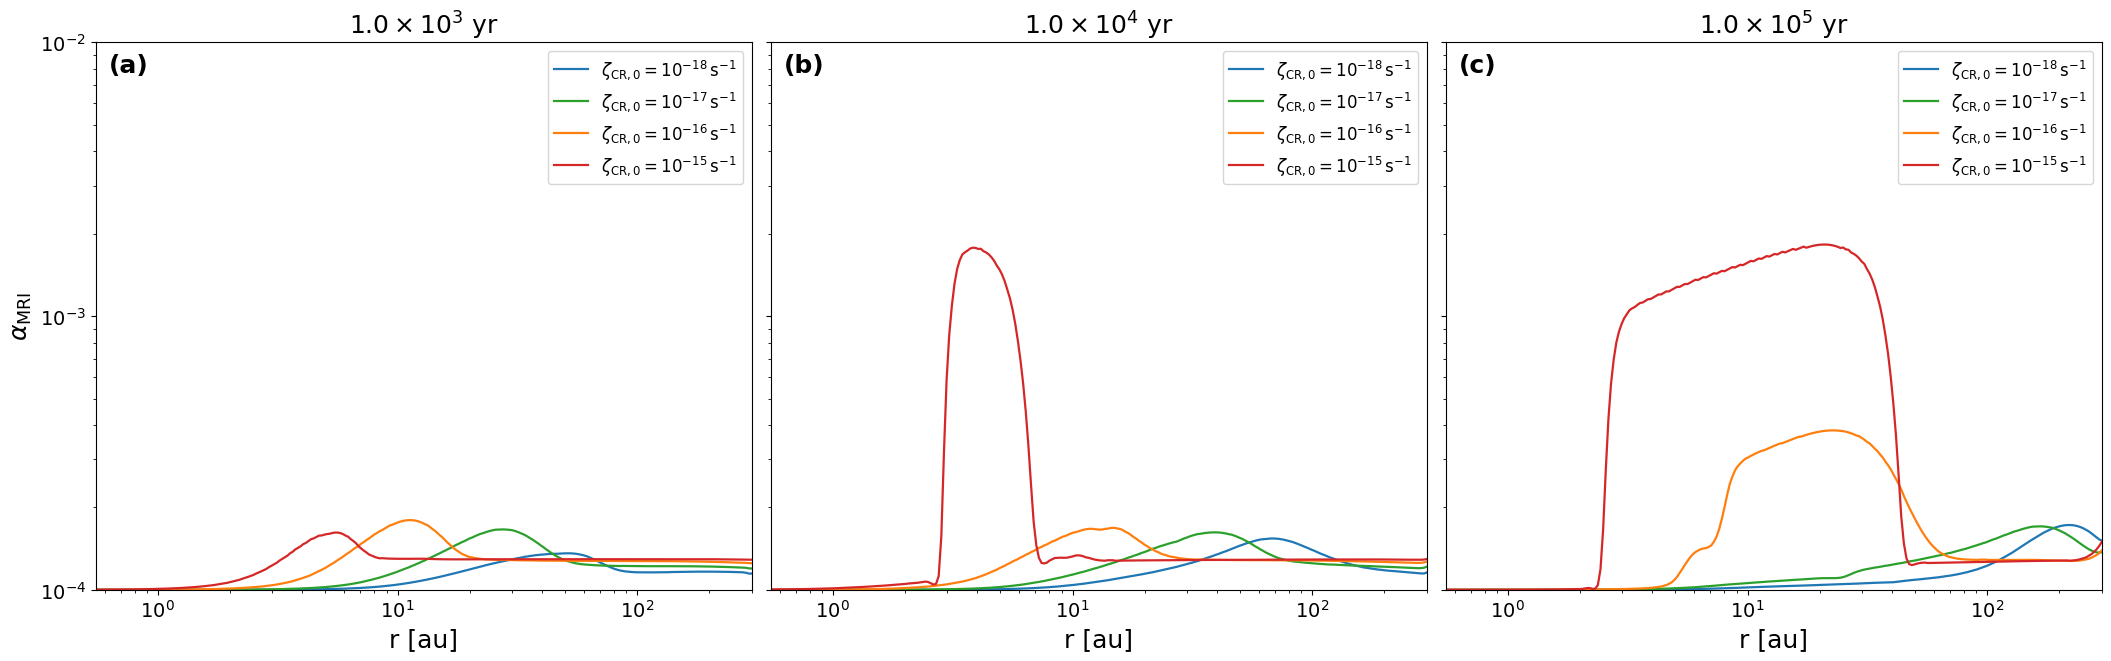

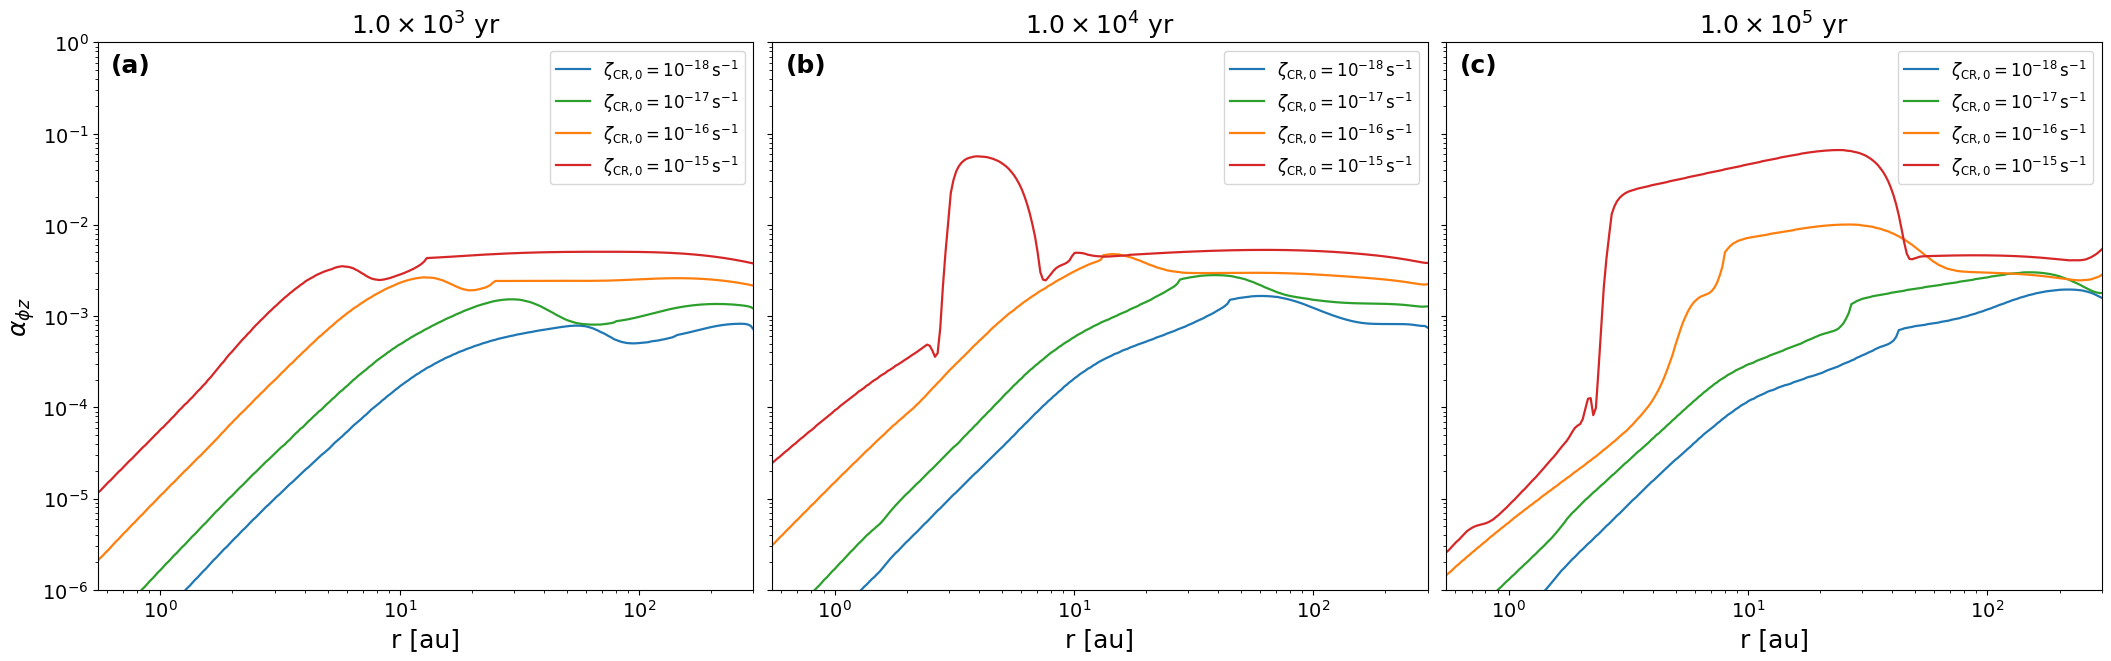

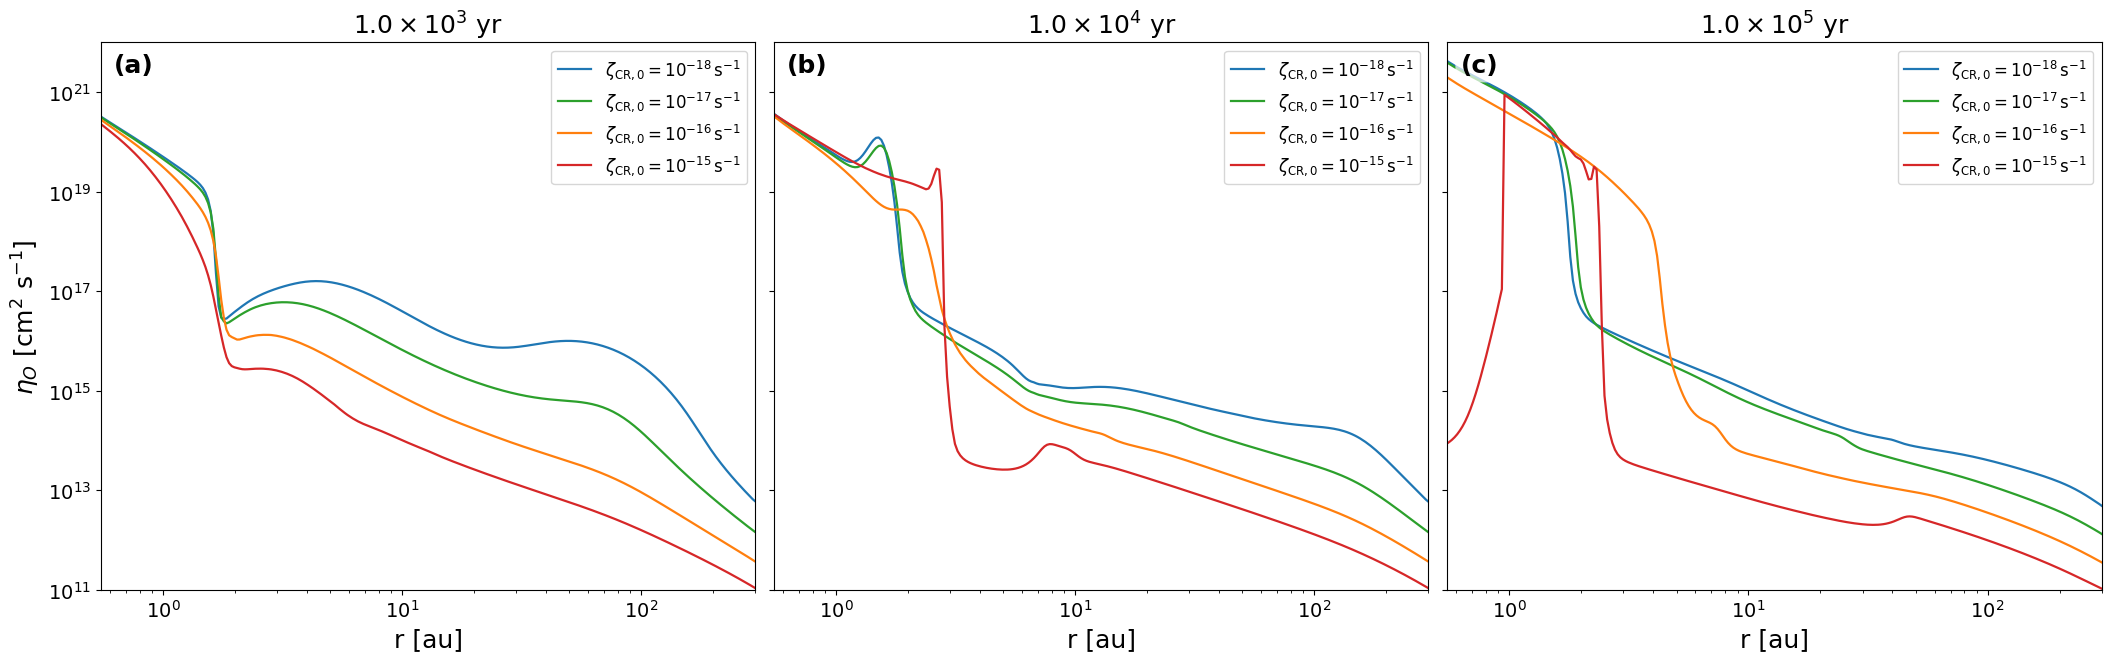

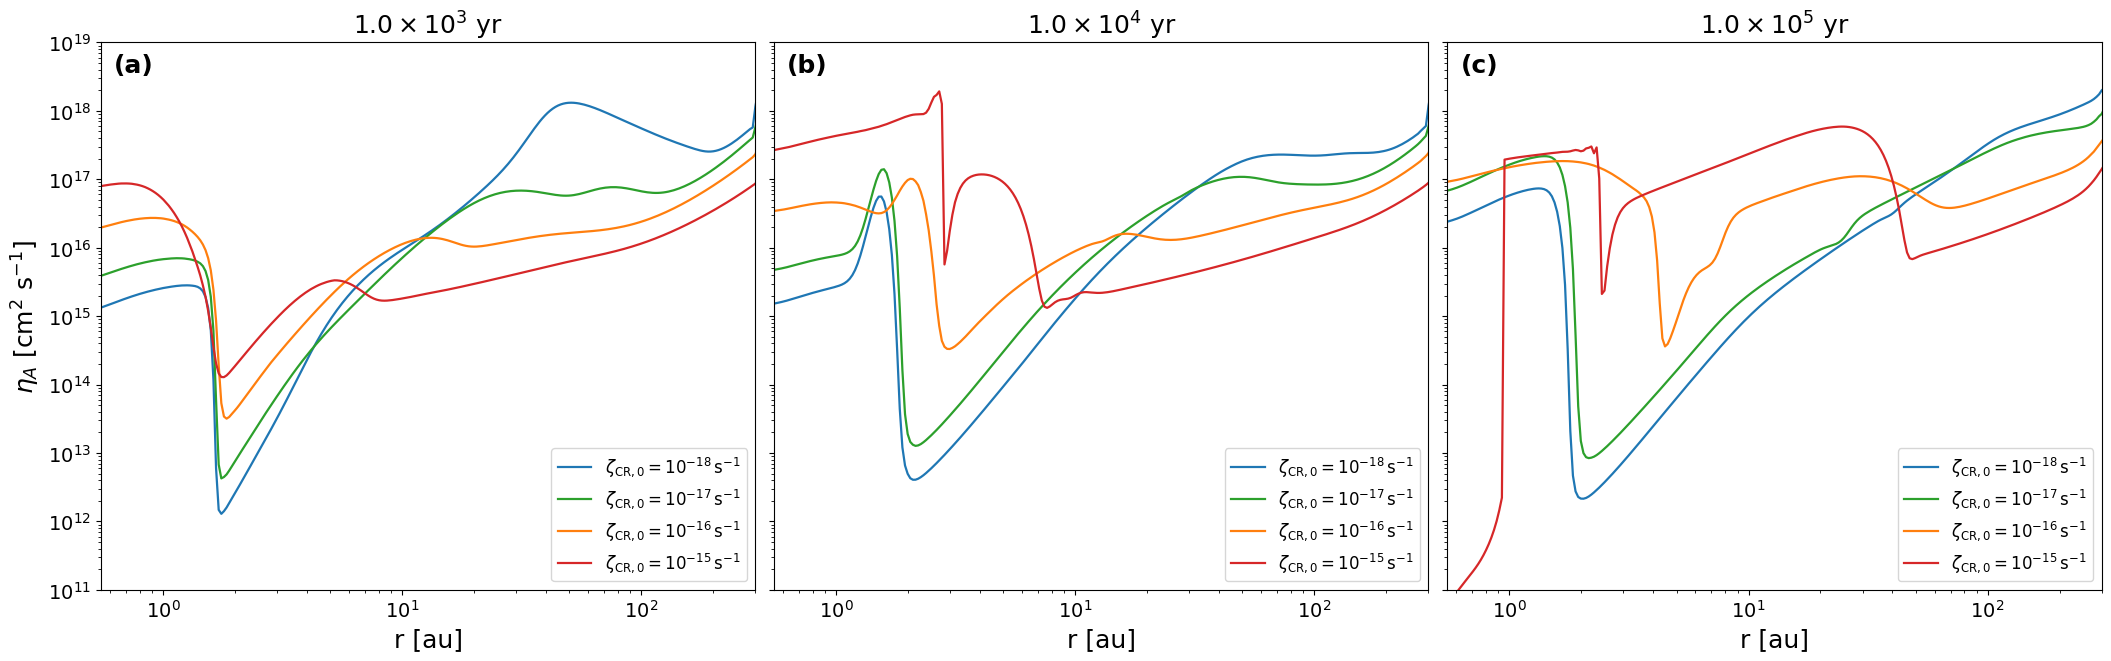

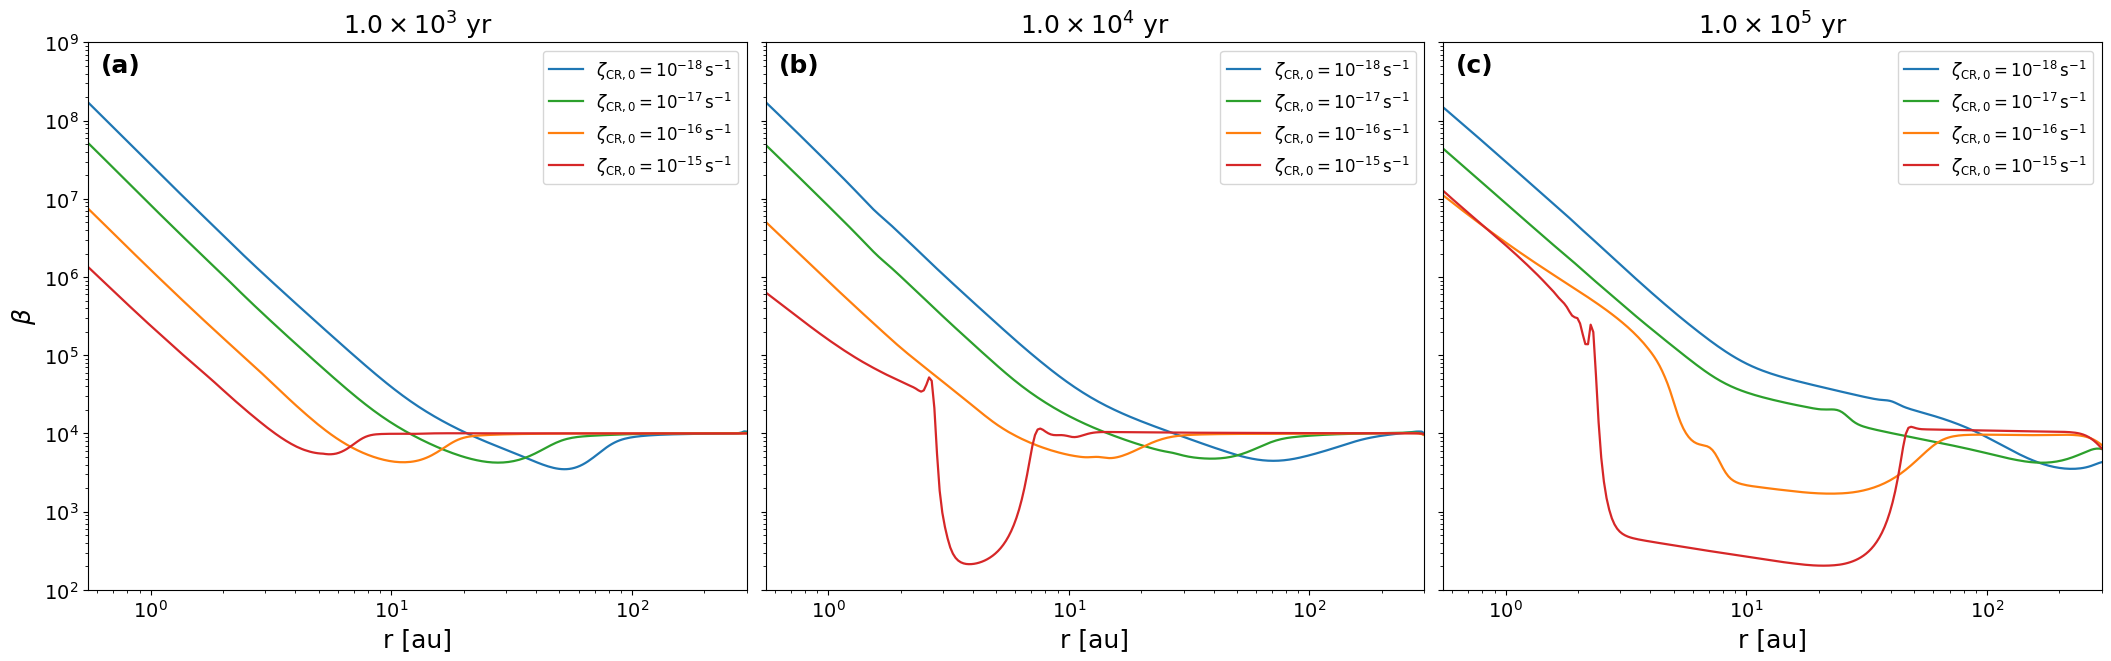

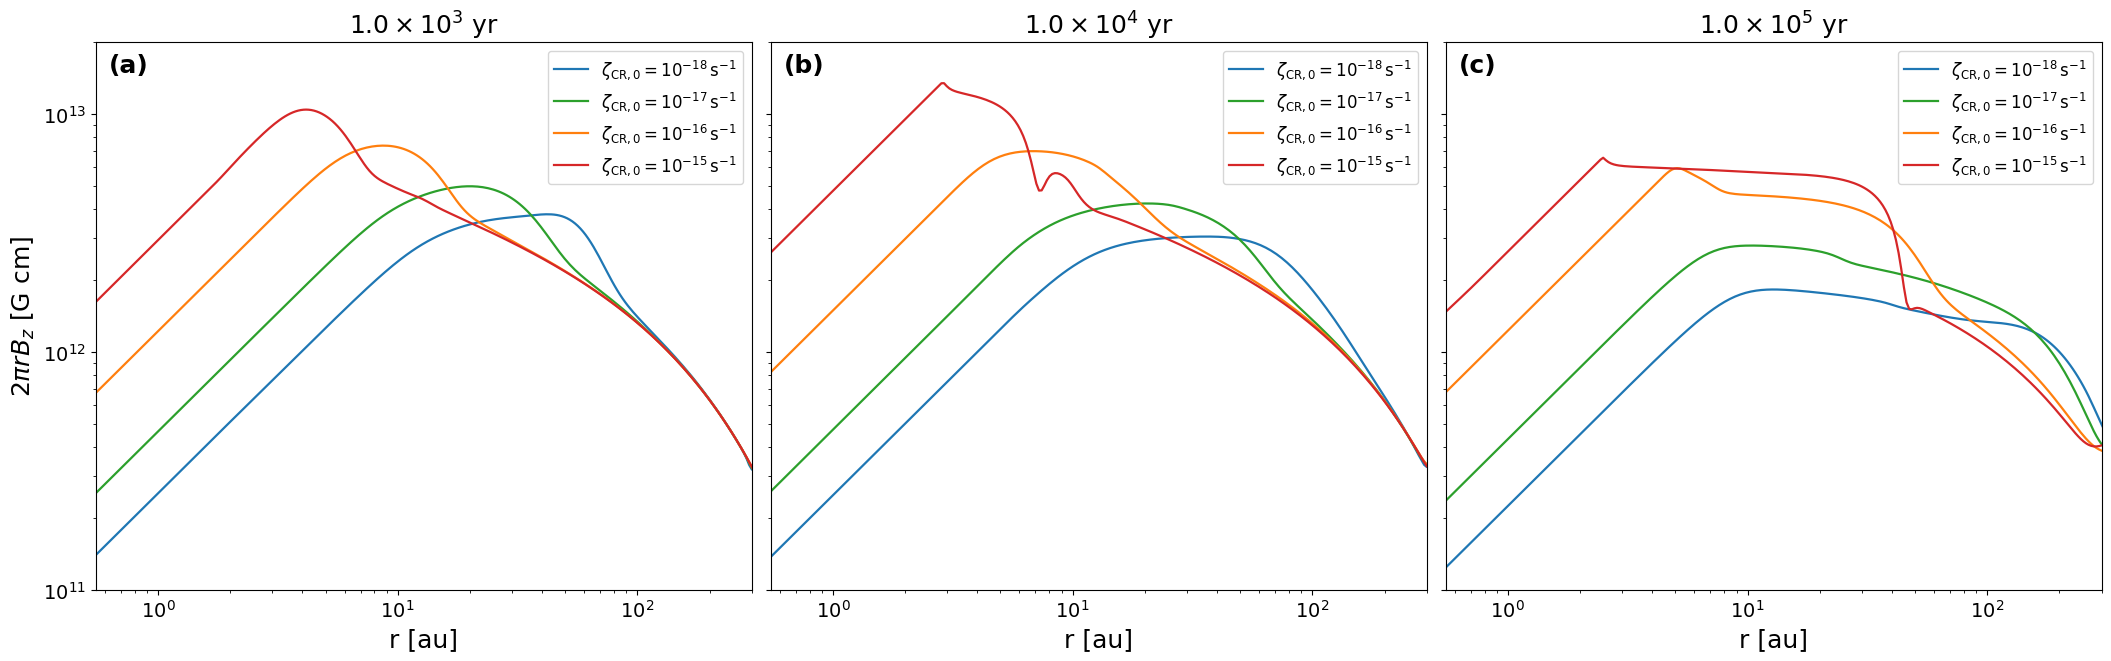

In [6]:
# ======================================================
# 3 時刻の動径分布のミニマップ (1x3, 1 パネル = 1 時刻, 色 = run)
#   図1: Sigma_g (実線) , Sigma_d,tot (破線)   図2: B_z   図3: T   図4: alpha_MRI   図5: alpha_phiz
#   図6: eta_O   図7: eta_A   図8: beta (中心面)   図9: 2 pi r B_z
# 凡例はすべてのパネルに付ける
# alpha_phiz は gas 列 17 (ALPHA_PHIZ = alpha_phiz = 0.75 sqrt(2 pi) (H_g/r) alpha_DW). 列 24 (alpha_DW_) は alpha_DW で別の量
# gas file 列: 1:Sigma_g 2:Sigma_d,tot 12:T 17:alpha_phiz 24:alpha_DW   B file 列: 1:alpha_MRI 2:B_z 3:eta_O 4:eta_A 5:beta
# ======================================================

times_mm = [1000, 10000, 100000]   # [yr] 全 run に出力がある時刻

# 縦軸の範囲 (物理量ごと. 3 時刻のパネルで共通)
ylim_sigma = (1.0e-2, 2.0e4)   # 図1: Sigma_g, Sigma_d,tot [g cm^-2]
ylim_B     = (1.0e-4, 1.0e-1)  # 図2: B_z [G]
ylim_T     = (1.0e1, 3.0e3)    # 図3: T [K]
ylim_aMRI  = (1.0e-4, 1.0e-2)  # 図4: alpha_MRI
ylim_aphiz = (1.0e-6, 1.0e0)   # 図5: alpha_phiz
ylim_etaO  = (1.0e11, 1.0e22)  # 図6: eta_O [cm^2 s^-1]
ylim_etaA  = (1.0e11, 1.0e19)  # 図7: eta_A [cm^2 s^-1]
ylim_beta  = (1.0e2, 1.0e9)    # 図8: beta
ylim_flux  = (1.0e11, 2.0e13)  # 図9: 2 pi r B_z [G cm]

# (ファイル, 列, 縦軸ラベル, 縦軸の範囲). ファイル "flux" は B file の B_z から 2 pi r B_z を作る
quantities_mm = [
    ("B", B_FIELD, r"$B_z$ [G]", ylim_B),
    ("gas", TEMP, r"$T$ [K]", ylim_T),
    ("B", ALPHA_MRI, r"$\alpha_{\rm MRI}$", ylim_aMRI),
    ("gas",ALPHA_PHIZ, r"$\alpha_{\phi z}$", ylim_aphiz),
    ("B", ETA_O, r"$\eta_O$ [cm$^2$ s$^{-1}$]", ylim_etaO),
    ("B", ETA_A, r"$\eta_A$ [cm$^2$ s$^{-1}$]", ylim_etaA),
    ("B", BETA_DISK, r"$\beta$", ylim_beta),
    ("flux", B_FIELD, r"$2\pi r B_z$ [G cm]", ylim_flux),
]

def minimap_axes(ylabel, ylim):
    fig, axes = plt.subplots(1, len(times_mm), figsize=(7 * len(times_mm), 6.5), sharey=True, layout="constrained")
    for ax, t in zip(axes, times_mm):
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlim(r_min, r_max)
        ax.set_ylim(*ylim)
        ax.set_xlabel("r [au]")
        ax.set_title(time_label_latex(t))
    axes[0].set_ylabel(ylabel)
    return fig, axes

run_handles = [Line2D([0], [0], color=run["color"], linewidth=1.6, label=run["label"]) for run in RUNS]

# ---- 図1: Sigma_g, Sigma_d,tot ----
fig, axes = minimap_axes(r"$\Sigma$  [g cm$^{-2}$]", ylim_sigma)
for ax, t in zip(axes, times_mm):
    for run in RUNS:
        gas = load_gas(run, t)
        r_AU = gas[:, GAS_R] / AU
        ax.plot(r_AU, gas[:, SIGMAG], color=run["color"], linewidth=1.6, linestyle="-")
        ax.plot(r_AU, gas[:, SIGMAD_TOT], color=run["color"], linewidth=1.6, linestyle="--")
# 凡例を2つに分ける (全パネル): 色 = run (zeta) は右上, 線種 = Sigma_g / Sigma_d,tot は左下
for ax in axes:
    leg_run = ax.legend(handles=run_handles, loc="upper right")
    ax.add_artist(leg_run)
    ax.legend(handles=[Line2D([0], [0], color="black", linewidth=1.6, linestyle="-", label=r"$\Sigma_g$"),
                       Line2D([0], [0], color="black", linewidth=1.6, linestyle="--", label=r"$\Sigma_{d,\rm tot}$")],
              loc="lower left")
plt.show()

# ---- 図2-9: B_z, T, alpha_MRI, alpha_phiz, eta_O, eta_A, beta, 2 pi r B_z ----
for kind, col, ylabel, ylim in quantities_mm:
    fig, axes = minimap_axes(ylabel, ylim)
    for ax, t in zip(axes, times_mm):
        for run in RUNS:
            gas = load_gas(run, t)
            r_AU = gas[:, GAS_R] / AU
            if kind == "gas":
                y = gas[:, col]
            elif kind == "B":
                y = load_B(run, t)[:, col]
            else:   # "flux"
                B = load_B(run, t)
                y = 2.0 * np.pi * B[:, MAG_R] * B[:, col]
            ax.plot(r_AU, np.where(y > 0.0, y, np.nan), color=run["color"], linewidth=1.6)
    for ax in axes:
        ax.legend(handles=run_handles, loc="best")
    plt.show()


## 第3パネル: 磁気拡散係数 と エルサッサー数 (1x2)

1つの図に2枚のミニマップ。同じ `time_label`, モデルごとに色分け、実線=Am(両極性拡散), 破線=Ohm(オーム散逸)。

- 磁気拡散係数: etaA(実線), etaO(破線) (B ファイル col4, col3, そのまま)。
- エルサッサー数: Lambda_A(実線), Lambda_O(破線) = V_A^2/(eta*Omega_K) (magnetic_field1D.cpp と同じ定義)。


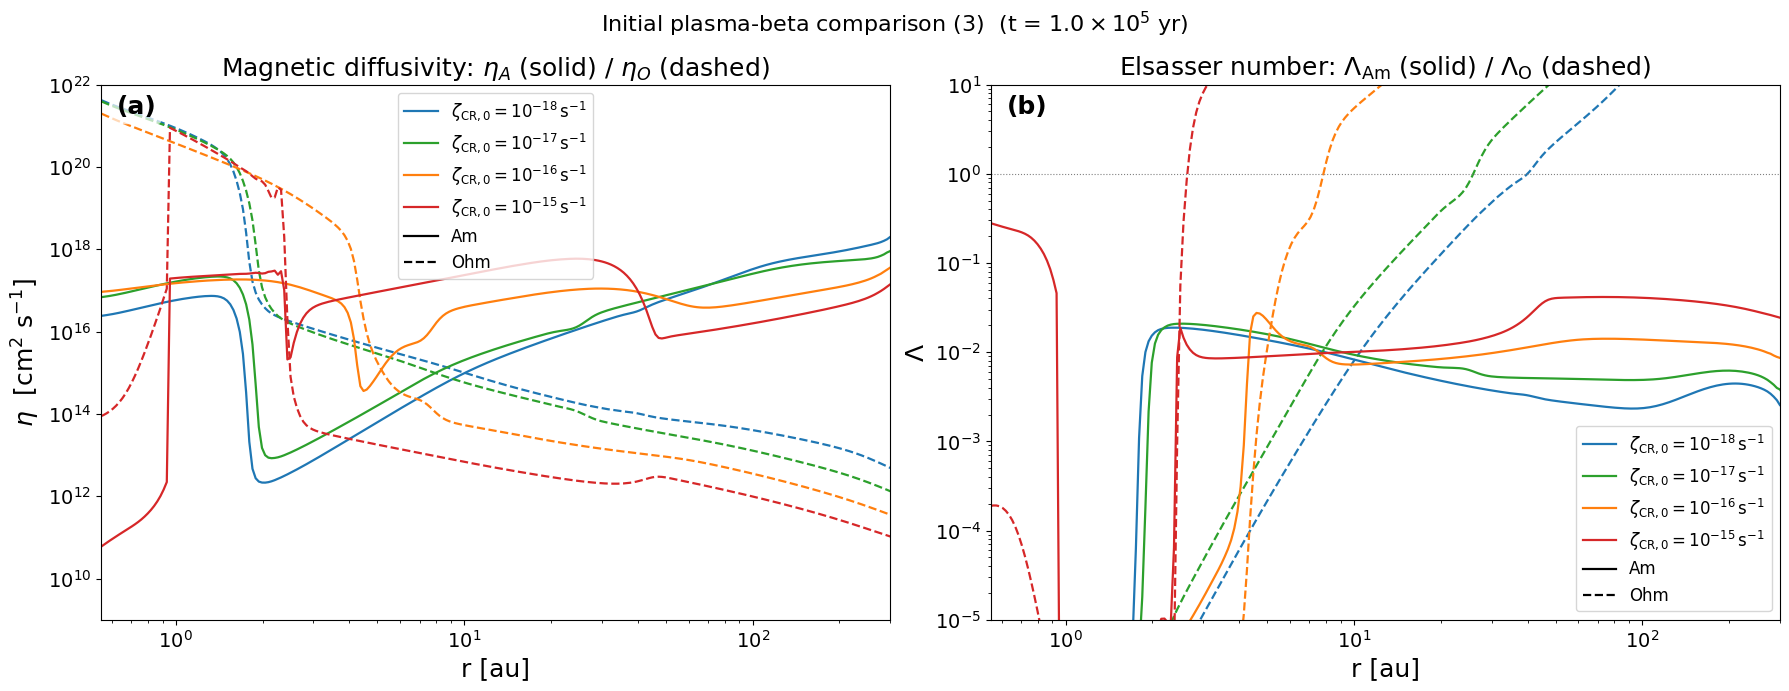

In [7]:
fig, (ax_eta, ax_els) = plt.subplots(1, 2, figsize=(18, 7))

for run in RUNS:
    gas = load_gas(run, time_label)
    r_AU = gas[:, GAS_R] / AU
    color, label = run['color'], run['label']

    B = load_B(run, time_label)
    ax_eta.plot(r_AU, B[:, ETA_A], color=color, linewidth=1.6, linestyle='-',  label=label)
    ax_eta.plot(r_AU, B[:, ETA_O], color=color, linewidth=1.6, linestyle='--')

    Lam_A, Lam_O = elsasser_numbers(run, time_label)
    ax_els.plot(r_AU, Lam_A, color=color, linewidth=1.6, linestyle='-',  label=label)
    ax_els.plot(r_AU, Lam_O, color=color, linewidth=1.6, linestyle='--')

# 色=run, 線種=Am(実線)/Ohm(破線) を1つの凡例にまとめる
style_handles = [
    Line2D([0], [0], color='black', linewidth=1.6, linestyle='-',  label='Am'),
    Line2D([0], [0], color='black', linewidth=1.6, linestyle='--', label='Ohm'),
]
run_handles = [Line2D([0], [0], color=run['color'], linewidth=1.6, label=run['label']) for run in RUNS]

ax_eta.set_xscale('log'); ax_eta.set_yscale('log')
ax_eta.set_xlim(r_min, r_max)
ax_eta.set_ylim(1.0e9, 1.0e22)
ax_eta.set_xlabel('r [au]'); ax_eta.set_ylabel(r'$\eta$  [cm$^2$ s$^{-1}$]')
ax_eta.set_title(r'Magnetic diffusivity: $\eta_A$ (solid) / $\eta_O$ (dashed)')
ax_eta.legend(handles=run_handles + style_handles, loc='best')

ax_els.set_xscale('log'); ax_els.set_yscale('log')
ax_els.set_xlim(r_min, r_max)
ax_els.set_ylim(1.0e-5, 1.0e1)
ax_els.set_xlabel('r [au]'); ax_els.set_ylabel(r'$\Lambda$')
ax_els.axhline(1.0, color='gray', linewidth=0.8, linestyle=':')
ax_els.set_title(r'Elsasser number: $\Lambda_{\rm Am}$ (solid) / $\Lambda_{\rm O}$ (dashed)')
ax_els.legend(handles=run_handles + style_handles, loc='best')

fig.suptitle(f'Initial plasma-beta comparison (3)  (t = {time_label_latex(time_label)})')
plt.tight_layout()
plt.show()


## 第4パネル: 加熱率(粘性 / wind / irradiation)比較 (1x2)

同じ `time_label`, モデルごとに色分け。実線=粘性加熱 $F_{\rm vis}$、破線=wind加熱 $F_{\rm wind}$、
点線=irradiation加熱 $F_{\rm irr}$(energy.cpp の `CalcViscousHeating()`/`CalcWindHeating()`/
`Calculate_Dt()` と同じ式、中間面温度版を保存済みの列から再構成)。

$F_{\rm irr}$ の元になる照射温度 $T_{\rm irr}(r)$ は `dust_disk.cpp` の `Initialization()` で
MMSNプロファイルとして1回だけ設定され、以降シミュレーション中ずっと更新されない
(= 円盤自身の温度進化とは独立な、時間に依存しない外部照射)。ただしそれを円盤内部の熱に
再処理する光学的厚み $\tau_R$ は $\Sigma_g(t)$・$T_{\rm mid}(t)$ 経由でわずかに時間発展するため、
$F_{\rm irr}$ 自体は厳密には時間に依存しないわけではない。

- 左: $F_{\rm vis}$(実線)・$F_{\rm wind}$(破線)・$F_{\rm irr}$(点線) を同じ軸に重ねる。
- 右: 比 $F_{\rm wind}/F_{\rm vis}$ -- どちらが支配的かを一目で見る(1 に水平線)。


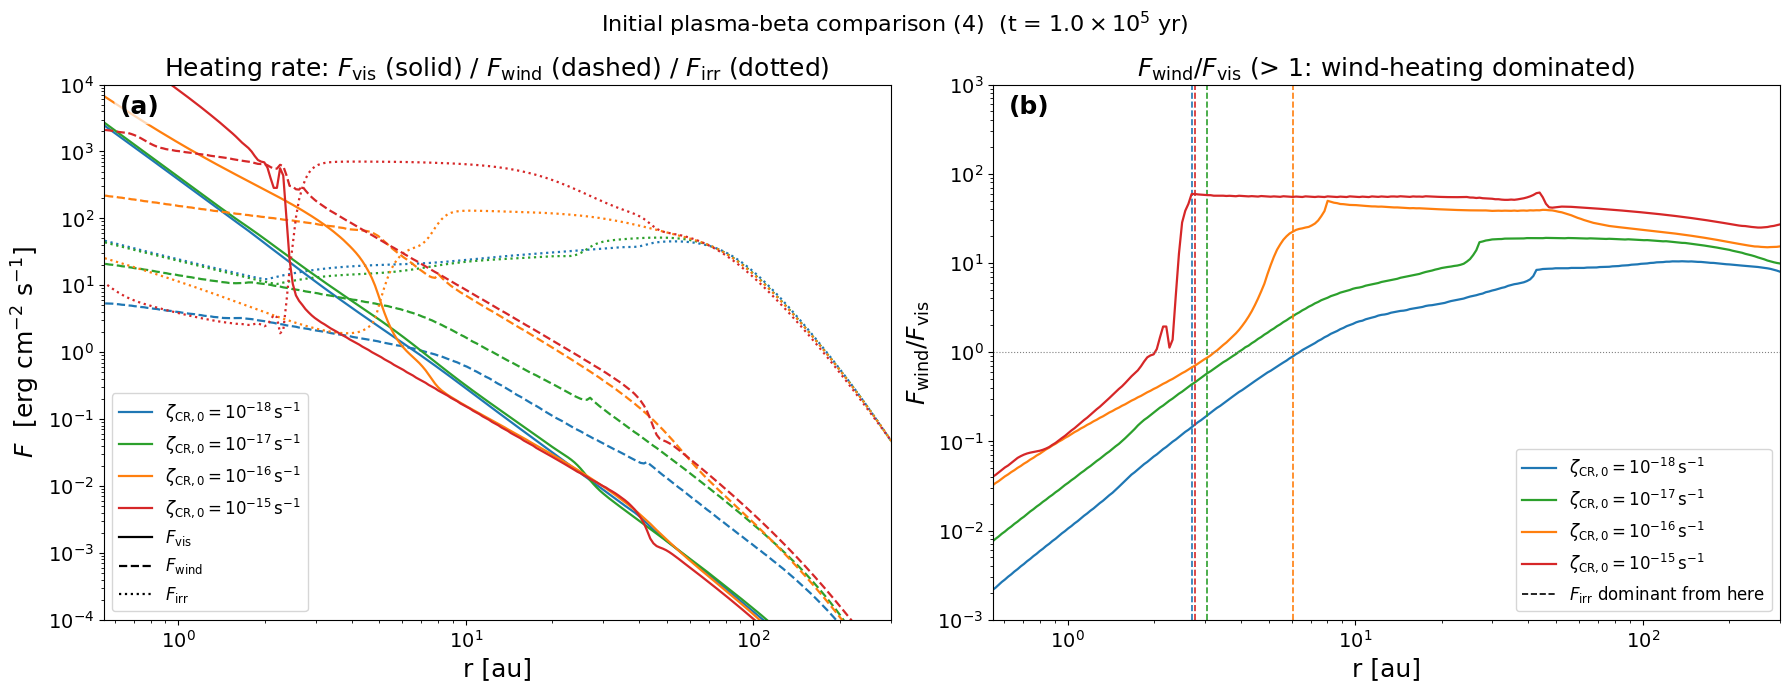

In [8]:
fig, (ax_heat, ax_ratio) = plt.subplots(1, 2, figsize=(18, 7))

for run in RUNS:
    gas = load_gas(run, time_label)
    r_AU = gas[:, GAS_R] / AU
    color, label = run['color'], run['label']

    F_vis, F_wind, F_irr = heating_rates(run, time_label)
    ax_heat.plot(r_AU, F_vis,  color=color, linewidth=1.6, linestyle='-',  label=label)
    ax_heat.plot(r_AU, F_wind, color=color, linewidth=1.6, linestyle='--')
    ax_heat.plot(r_AU, F_irr,  color=color, linewidth=1.6, linestyle=':')

    with np.errstate(divide='ignore', invalid='ignore'):
        ratio = F_wind / F_vis
    ax_ratio.plot(r_AU, ratio, color=color, linewidth=1.6, label=label)

    # F_irr が卓越し始める半径に縦線
    irr_dominant = F_irr > np.maximum(F_vis, F_wind)
    if irr_dominant.any():
        ax_ratio.axvline(r_AU[irr_dominant][0], color=color, linewidth=1.2, linestyle='--')

# 色=run, 線種=vis(実線)/wind(破線)/irr(点線) を1つの凡例にまとめる
style_handles = [
    Line2D([0], [0], color='black', linewidth=1.6, linestyle='-',  label=r'$F_{\rm vis}$'),
    Line2D([0], [0], color='black', linewidth=1.6, linestyle='--', label=r'$F_{\rm wind}$'),
    Line2D([0], [0], color='black', linewidth=1.6, linestyle=':',  label=r'$F_{\rm irr}$'),
]
run_handles = [Line2D([0], [0], color=run['color'], linewidth=1.6, label=run['label']) for run in RUNS]

ax_heat.set_xscale('log'); ax_heat.set_yscale('log')
ax_heat.set_xlim(r_min, r_max)
ax_heat.set_ylim(1.0e-4,1.0e4)
ax_heat.set_xlabel('r [au]'); ax_heat.set_ylabel(r'$F$  [erg cm$^{-2}$ s$^{-1}$]')
ax_heat.set_title(r'Heating rate: $F_{\rm vis}$ (solid) / $F_{\rm wind}$ (dashed) / $F_{\rm irr}$ (dotted)')
ax_heat.legend(handles=run_handles + style_handles, loc='best')

ax_ratio.set_xscale('log'); ax_ratio.set_yscale('log')
ax_ratio.set_xlim(r_min, r_max)
ax_ratio.set_ylim(1.0e-3,1.0e3)
ax_ratio.set_xlabel('r [au]'); ax_ratio.set_ylabel(r'$F_{\rm wind}/F_{\rm vis}$')
ax_ratio.axhline(1.0, color='gray', linewidth=0.8, linestyle=':')
ax_ratio.set_title(r'$F_{\rm wind}/F_{\rm vis}$ (> 1: wind-heating dominated)')
ax_ratio.legend(handles=run_handles + [
    Line2D([0], [0], color='black', linewidth=1.2, linestyle='--', label=r'$F_{\rm irr}$ dominant from here'),
], loc='best')

fig.suptitle(f'Initial plasma-beta comparison (4)  (t = {time_label_latex(time_label)})')
plt.tight_layout()
plt.show()


## 第5パネル: ダストサイズ分布 Sigma_d(r, a) 比較 (1xN ミニマップ)

同じ `time_label`, run ごとに1パネル。x = r [au], y = a_d [cm], 色 = ファイルの sigmad (= $d\Sigma_d/d\ln a$ [g cm$^{-2}$])。

- カラーバーは全 run 共通 (log, vmin = 1e-10, vmax = 1e2)。
- sigmad < 1e-15 は数値ノイズとして描かない(背景色)。
- シアン線: Sigma_d 重み付き平均ダスト半径 $\bar{a}_d$。


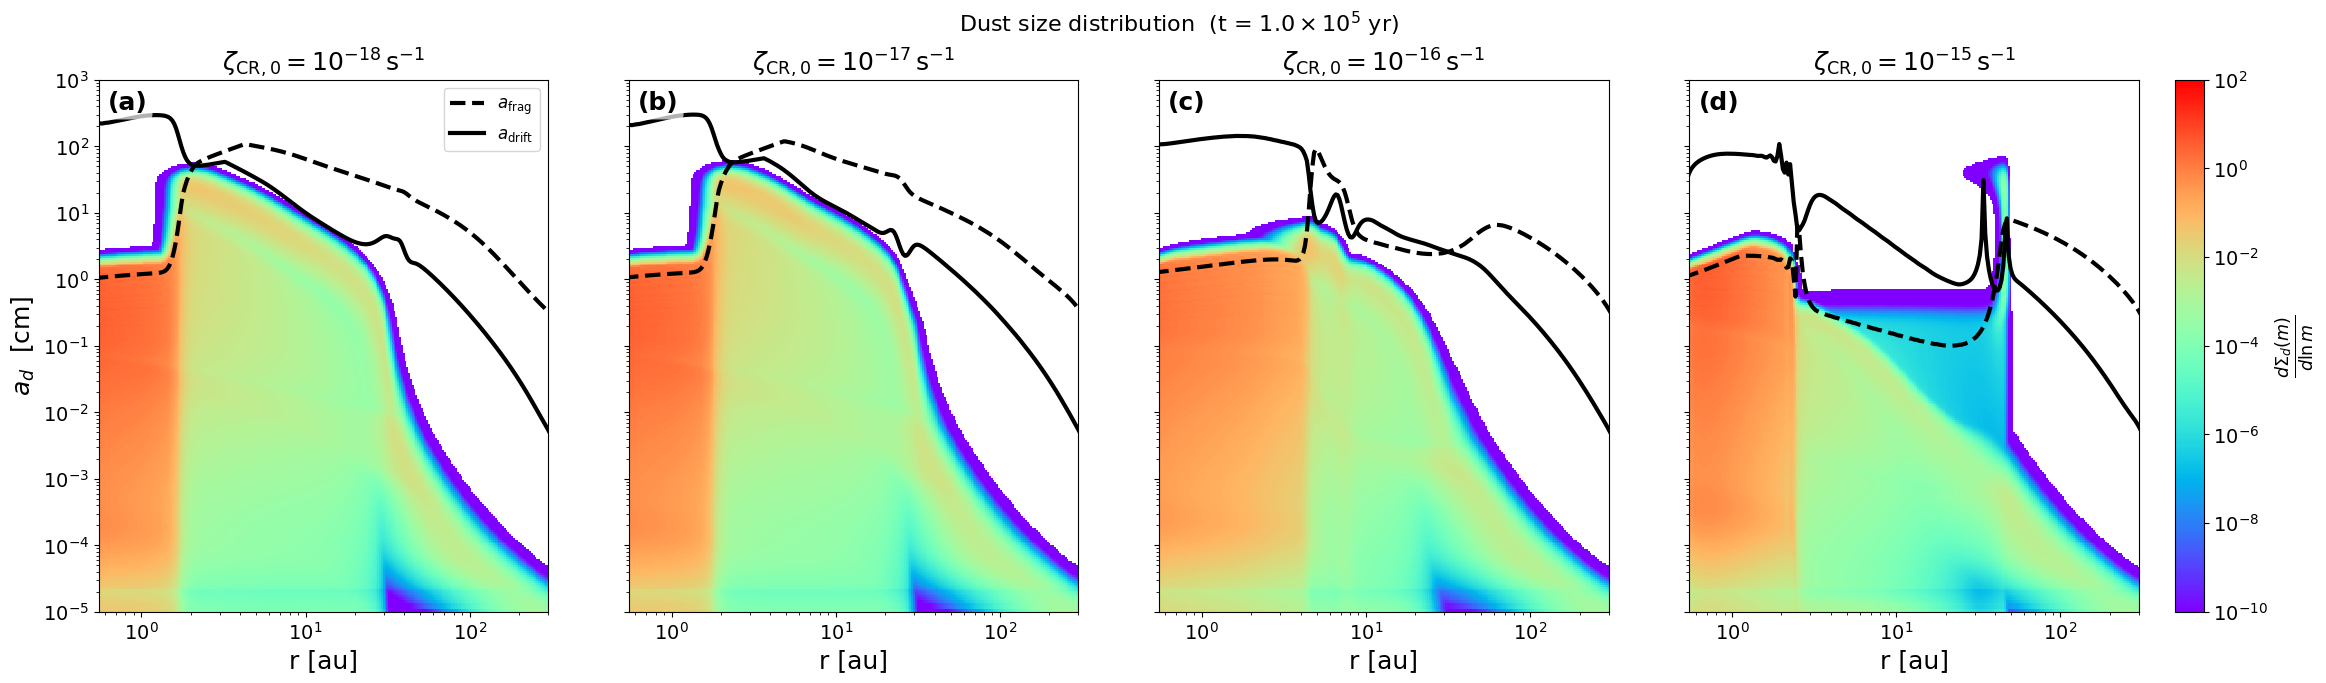

In [9]:
# ダストサイズ分布 Sigma_d(r, a) の run 間比較 (1xN ミニマップ). 色・カラーバー・限界サイズの線は analysis_snapshot.ipynb の図と同じ
#   St_frag  = f_f u_frag^2 / (3 alpha_MRI c_s^2) (Birnstiel et al. 2012), f_f = 0.87, u_frag は T = 160 K を境に 10 m/s (氷) と 1 m/s (シリケイト) を tanh でつなぐ
#   St_drift = f_d Sigma_d / (2 Sigma_g |eta_P|) , f_d = 0.55  (Epstein なら a_drift = f_d Sigma_d / (pi rho_s |eta_P|))
#   St -> a はコード (CalcStokesNumberAndDustScaleHeight) と同じ抵抗則を逆に解く:
#     Epstein (a < 9 lambda/4) : St = (pi/2) rho_s a / Sigma_g           -> a = 2 Sigma_g St / (pi rho_s)
#     Stokes  (a >= 9 lambda/4): St = (2 pi/9) rho_s a^2 / (lambda Sigma_g) -> a = sqrt(9 lambda Sigma_g St / (2 pi rho_s))
#     a = 9 lambda/4 で両者は一致するので, a_frag, a_drift は Epstein から Stokes にシームレスにつながる
#     lambda = 1/(n_mid sigma_H2) , n_mid = rho_mid/(mu m_H) , rho_mid = Sigma_g/(sqrt(2 pi) H_g) , sigma_H2 = 2e-15 cm^2
# gas file 列: 1:Sigma_g 12:T 19:eta_P   B file 列: 1:alpha_MRI
sigmad_vmin, sigmad_vmax = 1.0e-10, 1.0e2   # カラーバー範囲 [g cm^-2]
SIGMAD_MIN = 1.0e-15                        # これ未満は数値ノイズとして描かない
RHO_S = 1.4                                 # ダストの内部密度 [g cm^-3]
F_FRAG, F_DRIFT = 0.87, 0.55
SIGMA_H2 = 2.0e-15                          # H2 の衝突断面積 [cm^2] (コードと同じ)

def size_from_St(St, sigmag, mfp):
    # ストークス数 St に対応する粒径 [cm]. Epstein で求めた a が 9 lambda/4 以上なら Stokes 則で解き直す
    a_ep = 2.0 * sigmag * St / (np.pi * RHO_S)
    a_st = np.sqrt(9.0 * mfp * sigmag * St / (2.0 * np.pi * RHO_S))
    return np.where(a_ep < 2.25 * mfp, a_ep, a_st)

def size_limits(run, t, sigmad):
    # a_frag, a_drift [cm] (Epstein / Stokes をシームレスに切り替える)
    gas = load_gas(run, t)
    r_cm, sigmag, T, eta_P = gas[:, GAS_R], gas[:, SIGMAG], gas[:, TEMP], gas[:, ETA_P]
    alpha = load_B(run, t)[:, ALPHA_MRI]
    cs2 = kB * T / (mu * mH)
    Hg = np.sqrt(cs2) / np.sqrt(G * Msolar / r_cm**3)
    mfp = 1.0 / (sigmag / (np.sqrt(2.0 * np.pi) * Hg) / (mu * mH) * SIGMA_H2)
    w = 0.5 * (1.0 - np.tanh((T - 1.6e2) / 16.0))
    u_frag = w * 1.0e3 + (1.0 - w) * 1.0e2
    St_frag = F_FRAG * u_frag**2 / (3.0 * alpha * cs2)
    sig_d = np.where(np.abs(sigmad) > SIGMAD_MIN, sigmad, 0.0).sum(axis=0)
    St_drift = F_DRIFT * sig_d / (2.0 * sigmag * np.abs(eta_P))
    return size_from_St(St_frag, sigmag, mfp), size_from_St(St_drift, sigmag, mfp)

fig, axes = plt.subplots(1, len(RUNS), figsize=(6*len(RUNS), 7), sharex=True, sharey=True, squeeze=False)
norm = LogNorm(vmin=sigmad_vmin, vmax=sigmad_vmax)

for ax, run in zip(axes[0], RUNS):
    r_cm, a_bins, sigmad = load_dust(run, time_label)
    r_AU = r_cm / AU
    sig = np.where(sigmad >= SIGMAD_MIN, sigmad, np.nan)

    pc = ax.pcolormesh(r_AU, a_bins, sig, norm=norm, cmap=cm.rainbow, shading='nearest', rasterized=True)
    a_frag, a_drift = size_limits(run, time_label, sigmad)
    ax.plot(r_AU, a_frag, color='black', lw=3, ls='--', label=r'$a_\mathrm{frag}$')
    ax.plot(r_AU, a_drift, color='black', lw=3, ls='-', label=r'$a_\mathrm{drift}$')

    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlim(r_min, r_max)
    ax.set_ylim(1.0e-5,1.0e3)
    ax.set_xlabel('r [au]')
    ax.set_title(run['label'])

axes[0, 0].set_ylabel(r'$a_d$  [cm]')
axes[0, 0].legend(loc='upper right')

# カラーバーは右端に共通で置く (analysis_snapshot.ipynb と同じ)
fig.subplots_adjust(left=0.05, right=0.90, bottom=0.12, top=0.88, wspace=0.18)
cb = fig.colorbar(pc, cax=fig.add_axes([0.915, 0.12, 0.012, 0.76]), orientation='vertical')
cb.set_label(r'$ \frac{d\Sigma_d(m)}{d\ln m}  $')

fig.suptitle(f'Dust size distribution  (t = {time_label_latex(time_label)})')
plt.savefig(fig_path('dust_size_' + str(time_label) + '.png', RUNS, root=ANALYSIS_FIG_DIR), bbox_inches='tight')
plt.show()


## 第6パネル: r_ring, r_gap, Delta_I, delta_I の run 間比較 (2x2)

`gap_detection.ipynb` (r_disk/r_ring/r_gap, Yamaguchi et al. 2024 の定義) と同じ判定を、`RUNS` の各 run の全時刻に対して行う。

- $I_\nu = B_\nu(T)(1-e^{-\tau})$, $\tau = \sum_j \Sigma_{d,j}\kappa_{{\rm abs},j}$ ($\kappa_{\rm abs}$ は optool -dsharp)。`use_beam = True` ならガウスビームで畳み込んでから判定。
- r_ring / r_gap : $d\ln I/dr = 0$ の極大 / 極小。各 r_gap はその外側で最初の r_ring と組にする。
- $\Delta_{\rm I} = (r_{\rm out}-r_{\rm in})/r_{\rm out}$, $\delta_{\rm I} = I(r_{\rm ring})/I(r_{\rm gap})$。
- 色 = run。右下は Yamaguchi et al. (2024) Sec. 8.4 の回帰 ($r_{\rm ring} > 30$ au) と比較。


beta4_zeta1e18: 134 gaps detected
beta4: 155 gaps detected
beta4_zeta1e16: 0 gaps detected
beta4_zeta1e15: 113 gaps detected


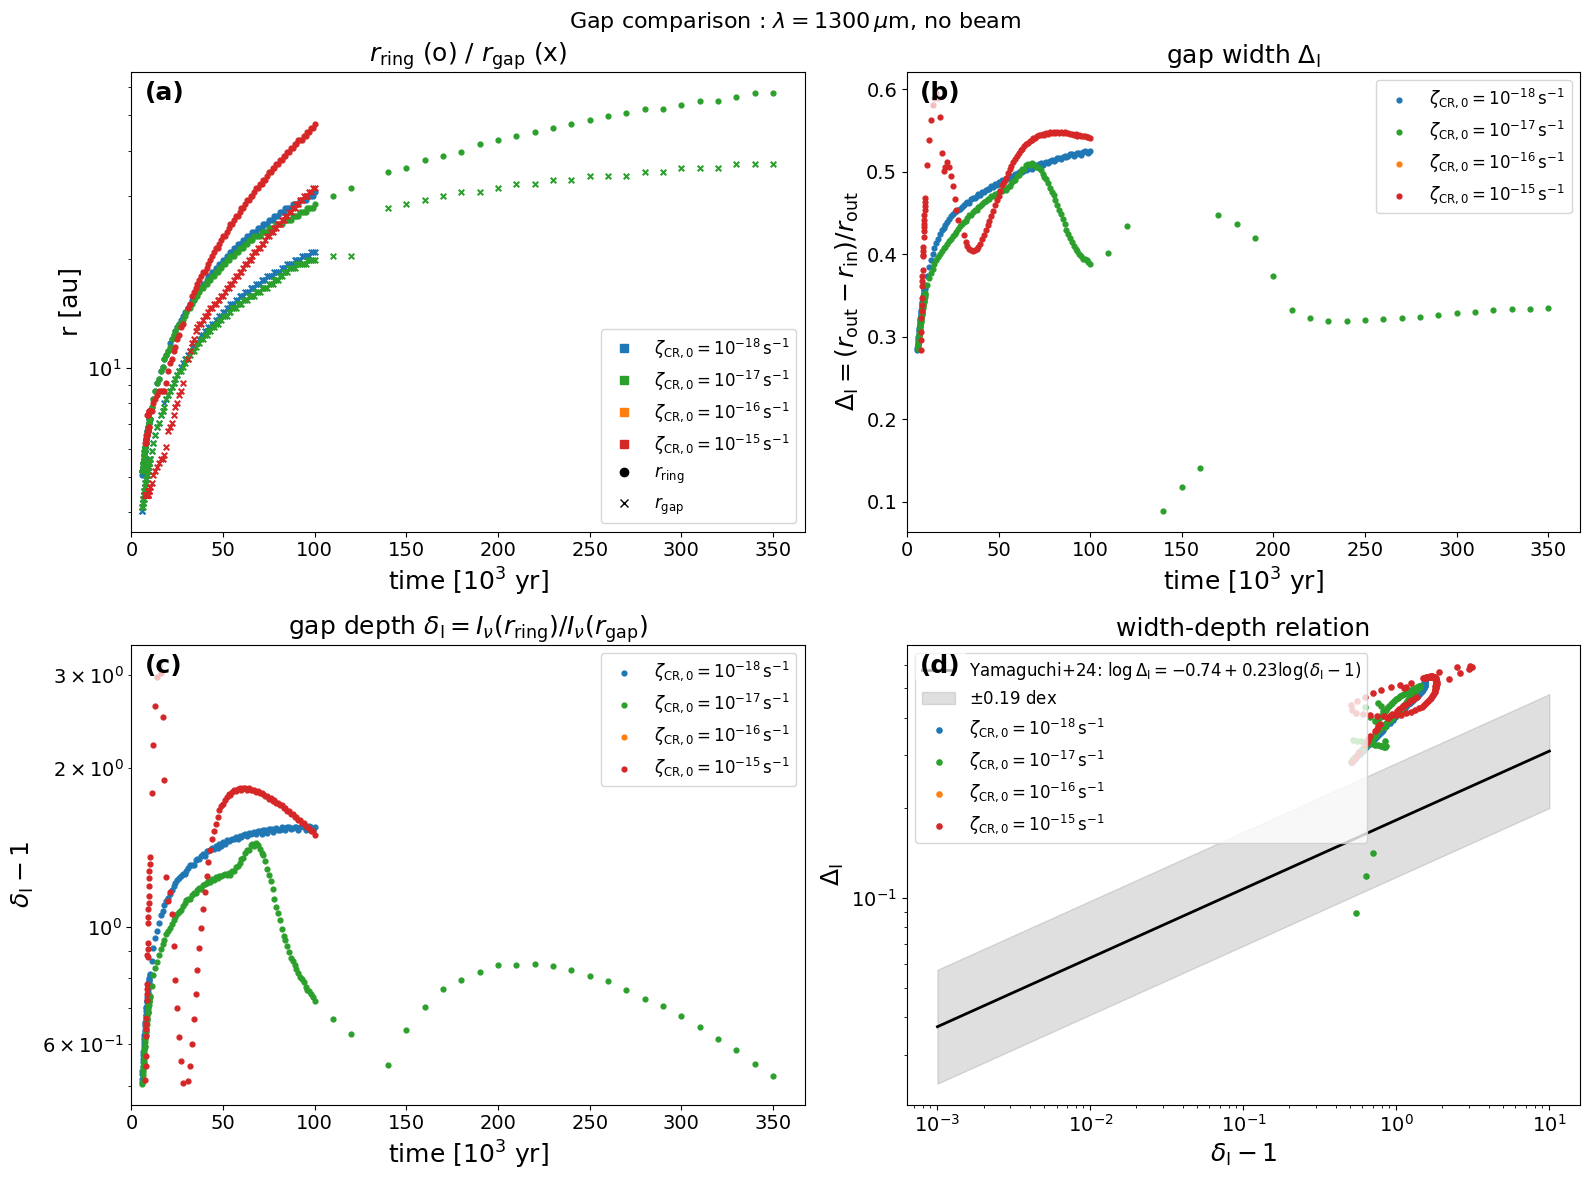

In [10]:
# ======================================================
# r_ring, r_gap, Delta_I, delta_I の run 間比較 (gap_detection.ipynb と同じ判定. 条件は thesis_common.ipynb)
# file 列: out (3行目: a_j, 5行目以降: 0:r_cen 1~:Sigma_d,j)   out_gas 1:Sigma_g 12:T
# ======================================================
import sys

os.environ["PATH"] = os.path.expanduser("~/bin") + ":" + os.environ["PATH"]

H_PLANCK = 6.62607015e-27     # erg s
C_LIGHT = 2.99792458e10       # cm s^-1

t_start_gap = 0             # これ以降の時刻を使う [yr]
paper_fit = (-0.74, 0.23, 0.19)   # Yamaguchi+24: log Delta_I = A + B log(delta_I - 1), sigma [dex]

def planck_nu(T, lambda_obs_micron):
    L = lambda_obs_micron * 1.0e-4
    expo = np.clip(H_PLANCK * C_LIGHT / (kB * T * L), None, 700.0)
    return 2.0 * H_PLANCK * C_LIGHT / L**3 / (np.exp(expo) - 1.0)

def crossing(r, I, I_edge, i0, i1, first):
    # r[i0]..r[i1] で I = I_edge を横切る位置 (線形補間). first=True: 最小の r, False: 最大の r
    j = np.where((I[i0:i1] - I_edge) * (I[i0 + 1:i1 + 1] - I_edge) <= 0.0)[0] + i0
    if len(j) == 0:
        return np.nan
    j = j[0] if first else j[-1]
    if I[j + 1] == I[j]:
        return r[j]
    return r[j] + (I_edge - I[j]) / (I[j + 1] - I[j]) * (r[j + 1] - r[j])

def find_radii(r, I, sigma_ratio, Hg):
    # r_disk : 成長曲線法
    F = np.concatenate(([0.0], np.cumsum(0.5 * (I[1:] * r[1:] + I[:-1] * r[:-1]) * np.diff(r)))) * 2.0 * np.pi
    r_disk = np.interp(flux_frac * F[-1], F, r)

    # D(r) = dlnI/dr の符号変化で極大(リング)・極小(ギャップ)
    with np.errstate(divide="ignore", invalid="ignore"):
        D = np.gradient(np.log(I), r)
    k = np.where(np.sign(D[:-1]) != np.sign(D[1:]))[0]
    i_ext = [i if I[i] * (1 if D[i] > 0 else -1) >= I[i + 1] * (1 if D[i] > 0 else -1) else i + 1 for i in k]
    kind = ["ring" if D[i] > 0 else "gap" for i in k]

    rings, gaps, edges_in, edges_out, depths = [], [], [], [], []
    for n, (i, kd) in enumerate(zip(i_ext, kind)):
        if kd != "gap" or n + 1 >= len(kind) or kind[n + 1] != "ring":
            continue
        i_ring = i_ext[n + 1]
        if use_rdisk_cut and r[i_ring] > r_disk:
            continue
        if use_delta_cut and I[i_ring] / I[i] < delta_min:
            continue
        if use_sigma_cut and sigma_ratio[i] >= sigma_ratio_max:
            continue
        if use_width_cut and r[i_ring] - r[i] < w_min_H * Hg[i]:
            continue
        gaps.append(r[i])
        rings.append(r[i_ring])
        depths.append(I[i_ring] / I[i])

        # ギャップの縁
        i_peak = i_ext[n - 1] if n >= 1 and kind[n - 1] == "ring" else 0
        I_edge = 0.5 * (I[i_ring] + I[i])                 # Case 1
        if I[i_peak] < I_edge:
            I_edge = 0.5 * (I[i_peak] + I[i])             # Case 2
        edges_in.append(crossing(r, I, I_edge, i_peak, i, first=True))
        edges_out.append(crossing(r, I, I_edge, i, i_ring, first=False))
    return r_disk, rings, gaps, edges_in, edges_out, depths

# ---- ビーム畳み込み行列 (全 run 共通) ----
beam_fwhm_au = beam_fwhm_arcsec * distance_pc   # 1" at d pc = d au
if use_beam:
    s_b = beam_fwhm_au / (2.0 * np.sqrt(2.0 * np.log(2.0))) * AU
    r_u = np.arange(0.5 * dr_conv, r_conv_max, dr_conv) * AU
    x = r_u[:, None] * r_u[None, :] / s_b**2
    W = (r_u[None, :] / s_b**2) * np.exp(-(r_u[:, None] - r_u[None, :])**2 / (2.0 * s_b**2)) * i0e(x) * dr_conv * AU
    del x

# ---- 吸収係数 (各ダストビン, optool -dsharp). ビンは全 run で同じであることを確認 ----
_, a_ref, _ = load_dust(RUNS[0], available_times(RUNS[0])[0])
for run in RUNS[1:]:
    _, a_run, _ = load_dust(run, available_times(run)[0])
    if a_run.shape != a_ref.shape or not np.allclose(a_run, a_ref):
        raise ValueError(f"{run['key']} のダストビンが {RUNS[0]['key']} と異なります (Kabs を共通にできません)")
Kabs_gap = []
for a in a_ref:
    cmd = "optool -dsharp -a {0} {0} -l {1} -print kabs".format(a * 1.0e4, Lambda_obs)
    out = subprocess.run(cmd, shell=True, capture_output=True, text=True).stdout
    Kabs_gap.append(float(out.strip().split()[-1]))
Kabs_gap = np.array(Kabs_gap)

# ---- 各 run, 各時刻で判定 ----
gap_results = {}
for run in RUNS:
    sigmag_ini = load_gas(run, 0)[:, SIGMAG]
    M_star = Msolar
    with open(run["dir"] + "/input") as f:
        for line in f:
            if line.split("//")[0].split("=")[0].strip() == "star_mass":
                M_star = float(line.split("//")[0].split("=")[1]) * Msolar
    res = {k: [] for k in ("t_ring", "r_ring", "t_gap", "r_gap", "r_in", "r_out", "delta_I")}
    for year in [t for t in available_times(run) if t >= t_start_gap]:
        r, _, sigmad = load_dust(run, year)
        gas = load_gas(run, year)
        sigmag, T = gas[:, SIGMAG], gas[:, TEMP]
        sigmad = np.where(np.abs(sigmad) > 1.0e-50, sigmad, 0.0)
        I = planck_nu(T, Lambda_obs) * (1.0 - np.exp(-(Kabs_gap @ sigmad))) * 1.0e23   # Jy/sr
        Hg = np.sqrt(kB * T / (mu * mH)) / np.sqrt(G * M_star / r**3)
        if use_beam:
            I_u = np.interp(r_u, r, I, left=0.0, right=0.0)
            _, rings, gaps, e_in, e_out, depths = find_radii(r_u, W @ I_u, np.interp(r_u, r, sigmag / sigmag_ini), np.interp(r_u, r, Hg))
        else:
            _, rings, gaps, e_in, e_out, depths = find_radii(r, I, sigmag / sigmag_ini, Hg)
        res["t_ring"] += [year] * len(rings)
        res["r_ring"] += rings
        res["t_gap"] += [year] * len(gaps)
        res["r_gap"] += gaps
        res["r_in"] += e_in
        res["r_out"] += e_out
        res["delta_I"] += depths
    res = {k: np.array(v, dtype=float) for k, v in res.items()}
    res["Delta_I"] = (res["r_out"] - res["r_in"]) / res["r_out"]
    gap_results[run["key"]] = res
    print(f"{run['key']}: {len(res['t_gap'])} gaps detected")

# ---- 図 ----
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
ax_pos, ax_D, ax_d, ax_rel = axes.flat
x_fit = np.logspace(-3, 1, 100)
A_fit, B_fit, sig_fit = paper_fit
y_fit = 10.0**(A_fit + B_fit * np.log10(x_fit))
ax_rel.plot(x_fit, y_fit, color="black", lw=2,
            label=r"Yamaguchi+24: $\log\Delta_{{\rm I}} = {:.2f} + {:.2f}\log(\delta_{{\rm I}}-1)$".format(A_fit, B_fit))
ax_rel.fill_between(x_fit, y_fit * 10.0**-sig_fit, y_fit * 10.0**sig_fit, color="gray", alpha=0.25,
                    label=r"$\pm{:.2f}$ dex".format(sig_fit))

for run in RUNS:
    res, color = gap_results[run["key"]], run["color"]
    tg = res["t_gap"] / 1.0e3
    ax_pos.scatter(res["t_ring"] / 1.0e3, res["r_ring"] / AU, s=12, marker="o", color=color)
    ax_pos.scatter(tg, res["r_gap"] / AU, s=16, marker="x", color=color)
    ax_D.scatter(tg, res["Delta_I"], s=12, color=color, label=run["label"])
    ax_d.scatter(tg, res["delta_I"] - 1.0, s=12, color=color, label=run["label"])
    ok = np.isfinite(res["Delta_I"]) & (res["delta_I"] > 1.0)
    ax_rel.scatter(res["delta_I"][ok] - 1.0, res["Delta_I"][ok], s=14, color=color, label=run["label"], zorder=3)

ax_pos.set_yscale("log")
ax_pos.set_ylabel("r [au]")
ax_pos.set_title(r"$r_{\rm ring}$ (o) / $r_{\rm gap}$ (x)")
ax_pos.legend(handles=[Line2D([0], [0], color=run["color"], lw=0, marker="s", label=run["label"]) for run in RUNS] + [
    Line2D([0], [0], color="black", lw=0, marker="o", label=r"$r_{\rm ring}$"),
    Line2D([0], [0], color="black", lw=0, marker="x", label=r"$r_{\rm gap}$")], loc="best")

ax_D.set_ylabel(r"$\Delta_{\rm I} = (r_{\rm out}-r_{\rm in})/r_{\rm out}$")
ax_D.set_title(r"gap width $\Delta_{\rm I}$")
ax_D.legend(loc="best")

ax_d.set_yscale("log")
ax_d.set_ylabel(r"$\delta_{\rm I} - 1$")
ax_d.set_title(r"gap depth $\delta_{\rm I} = I_\nu(r_{\rm ring})/I_\nu(r_{\rm gap})$")
ax_d.legend(loc="best")

for ax in (ax_pos, ax_D, ax_d):
    ax.set_xlim(left=0.0)
    ax.set_xlabel(r"time [$10^3$ yr]")

ax_rel.set_xscale("log"); ax_rel.set_yscale("log")
ax_rel.set_xlabel(r"$\delta_{\rm I} - 1$")
ax_rel.set_ylabel(r"$\Delta_{\rm I}$")
ax_rel.set_title("width-depth relation")
ax_rel.legend(loc="upper left")

beam_label = (r"beam {}$^{{\prime\prime}}$ @ {:.0f} pc ({:.0f} au)".format(beam_fwhm_arcsec, distance_pc, beam_fwhm_au)
              if use_beam else "no beam")
fig.suptitle(r"Gap comparison : $\lambda = {:.0f}\,\mu$m, ".format(Lambda_obs) + beam_label)
plt.tight_layout()
plt.show()


## 第7パネル: ギャップが開いてからの時間 $(t-t_{\rm open})\,\Omega$ に対する幅 $\Delta_{\rm I}$・深さ $\delta_{\rm I}$ の run 間比較 (1x2)

第6パネルの `gap_results` を使う。

1. 各 run で時刻ごとのギャップを r_gap の近さで時間方向につなぎ、ギャップごとのトラックを作る(thesis.ipynb の t_ref のセルと同じ):
   $|\ln(r_{\rm gap}/r_{\rm gap,前回})| <$ `match_tol` かつ前回の検出から `max_miss` スナップショット以内なら同じギャップ。点数が `min_points` 未満のトラックは除く。
2. $t_{\rm open}$ = そのトラックが最初に検出された時刻。
3. 横軸 $x = (t-t_{\rm open})\,\Omega(r_{\rm gap}(t_{\rm open}))$, $\Omega = \sqrt{GM_\odot/r^3}$。
   `integrate_orbits = True` なら $x = \int_{t_{\rm open}}^{t}\Omega(r_{\rm gap}(t'))\,dt'$。

色 = run、マーカー = 同じ run 内のギャップ(内側から順)。


beta4_zeta1e18: 1 gap tracks
beta4: 2 gap tracks
beta4_zeta1e16: 0 gap tracks
beta4_zeta1e15: 2 gap tracks


/tmp/ipykernel_348921/2112278009.py:64: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax_d.set_ylim(0.0,2.0e0)


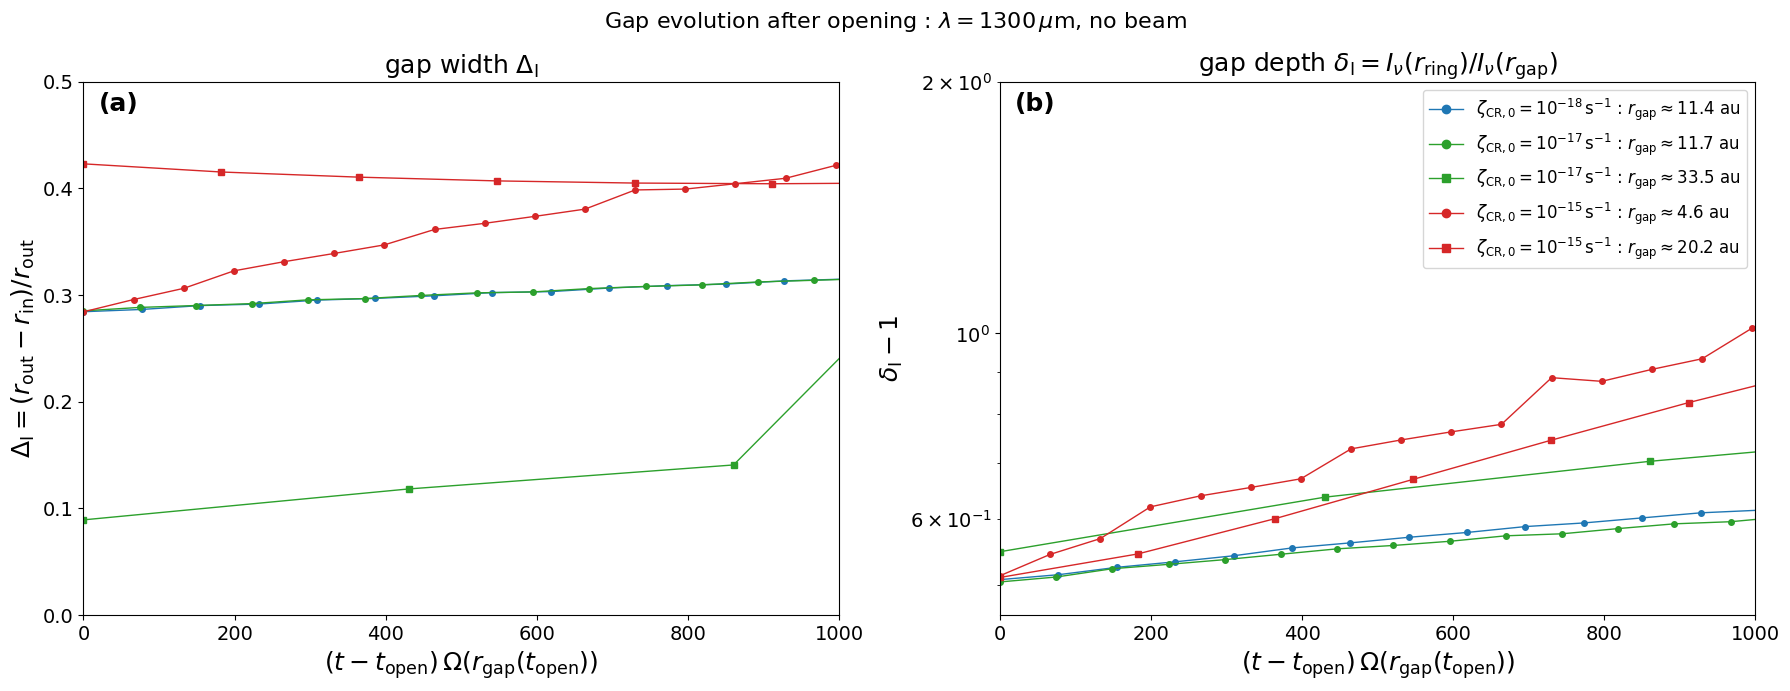

In [11]:
match_tol = 0.15          # 同じギャップとみなす |ln(r_gap/r_gap,前回)| の上限
max_miss = 3              # 検出が途切れてもつなぐスナップショット数
min_points = 10           # これより点数の少ないトラックは除外
integrate_orbits = False  # True: r_gap の移動を考慮して int Omega dt
only_innermost = False    # True: 各 run の一番内側のギャップだけ描く
gap_markers = ["o", "s", "^", "v", "D", "P", "*", "X", "<", ">"]

def omega_K(r_cm):
    return np.sqrt(G_cgs * Msolar / r_cm**3)   # [s^-1]

def track_gaps(t_gap, r_gap):
    # 時刻ごとのギャップを r_gap の近さでつなぐ. 戻り値: index 配列のリスト (t_open での r_gap の小さい順)
    t_snap = np.array(sorted(set(t_gap)))
    tracks = []
    for k, ts in enumerate(t_snap):
        used = set()
        for j in np.where(t_gap == ts)[0]:
            best, best_d = None, match_tol
            for n, tr in enumerate(tracks):
                if n in used or k - tr["last_k"] > max_miss:
                    continue
                d = abs(np.log(r_gap[j] / tr["last_r"]))
                if d < best_d:
                    best, best_d = n, d
            if best is None:
                tracks.append({"idx": [], "last_r": None, "last_k": None})
                best = len(tracks) - 1
            tracks[best]["idx"].append(j)
            tracks[best]["last_r"], tracks[best]["last_k"] = r_gap[j], k
            used.add(best)
    tracks = [np.array(tr["idx"]) for tr in tracks if len(tr["idx"]) >= min_points]
    tracks.sort(key=lambda idx: r_gap[idx[0]])
    return tracks

fig, (ax_W, ax_d) = plt.subplots(1, 2, figsize=(18, 7), sharex=True)
legend_handles = []
for run in RUNS:
    res, color = gap_results[run["key"]], run["color"]
    tracks = track_gaps(res["t_gap"], res["r_gap"])
    if only_innermost:
        tracks = tracks[:1]
    print(f"{run['key']}: {len(tracks)} gap tracks")
    for n, idx in enumerate(tracks):
        t_tr = res["t_gap"][idx] * YEAR      # [s]
        rg_tr = res["r_gap"][idx]            # [cm]
        if integrate_orbits:
            Om = omega_K(rg_tr)
            x = np.concatenate(([0.0], np.cumsum(0.5 * (Om[1:] + Om[:-1]) * np.diff(t_tr))))
        else:
            x = (t_tr - t_tr[0]) * omega_K(rg_tr[0])
        mk = gap_markers[n % len(gap_markers)]
        ax_W.plot(x, res["Delta_I"][idx], marker=mk, ms=4, lw=1.0, color=color)
        ax_d.plot(x, res["delta_I"][idx] - 1.0, marker=mk, ms=4, lw=1.0, color=color)
        legend_handles.append(Line2D([0], [0], color=color, marker=mk, lw=1.0,
                                     label=r"{} : $r_{{\rm gap}} \approx {:.1f}$ au".format(run["label"], np.median(rg_tr) / AU)))

xlabel = (r"$\int_{t_{\rm open}}^{t} \Omega(r_{\rm gap})\,dt'$" if integrate_orbits
          else r"$(t - t_{\rm open})\,\Omega(r_{\rm gap}(t_{\rm open}))$")
ax_W.set_ylabel(r"$\Delta_{\rm I} = (r_{\rm out}-r_{\rm in})/r_{\rm out}$")
ax_W.set_title(r"gap width $\Delta_{\rm I}$")
ax_W.set_ylim(0.0,0.5)
ax_d.set_yscale("log")
ax_d.set_xlim(0.0,1.0e3)
ax_d.set_ylim(0.0,2.0e0)
ax_d.set_ylabel(r"$\delta_{\rm I} - 1$")
ax_d.set_title(r"gap depth $\delta_{\rm I} = I_\nu(r_{\rm ring})/I_\nu(r_{\rm gap})$")
for ax in (ax_W, ax_d):
    ax.set_xlim(left=0.0)
    ax.set_xlabel(xlabel)
ax_d.legend(handles=legend_handles, loc="best")

fig.suptitle(r"Gap evolution after opening : $\lambda = {:.0f}\,\mu$m, ".format(Lambda_obs) + beam_label)
plt.tight_layout()
plt.show()


## C = t_adv/t_diff の時空図の比較 (1xN ミニマップ)

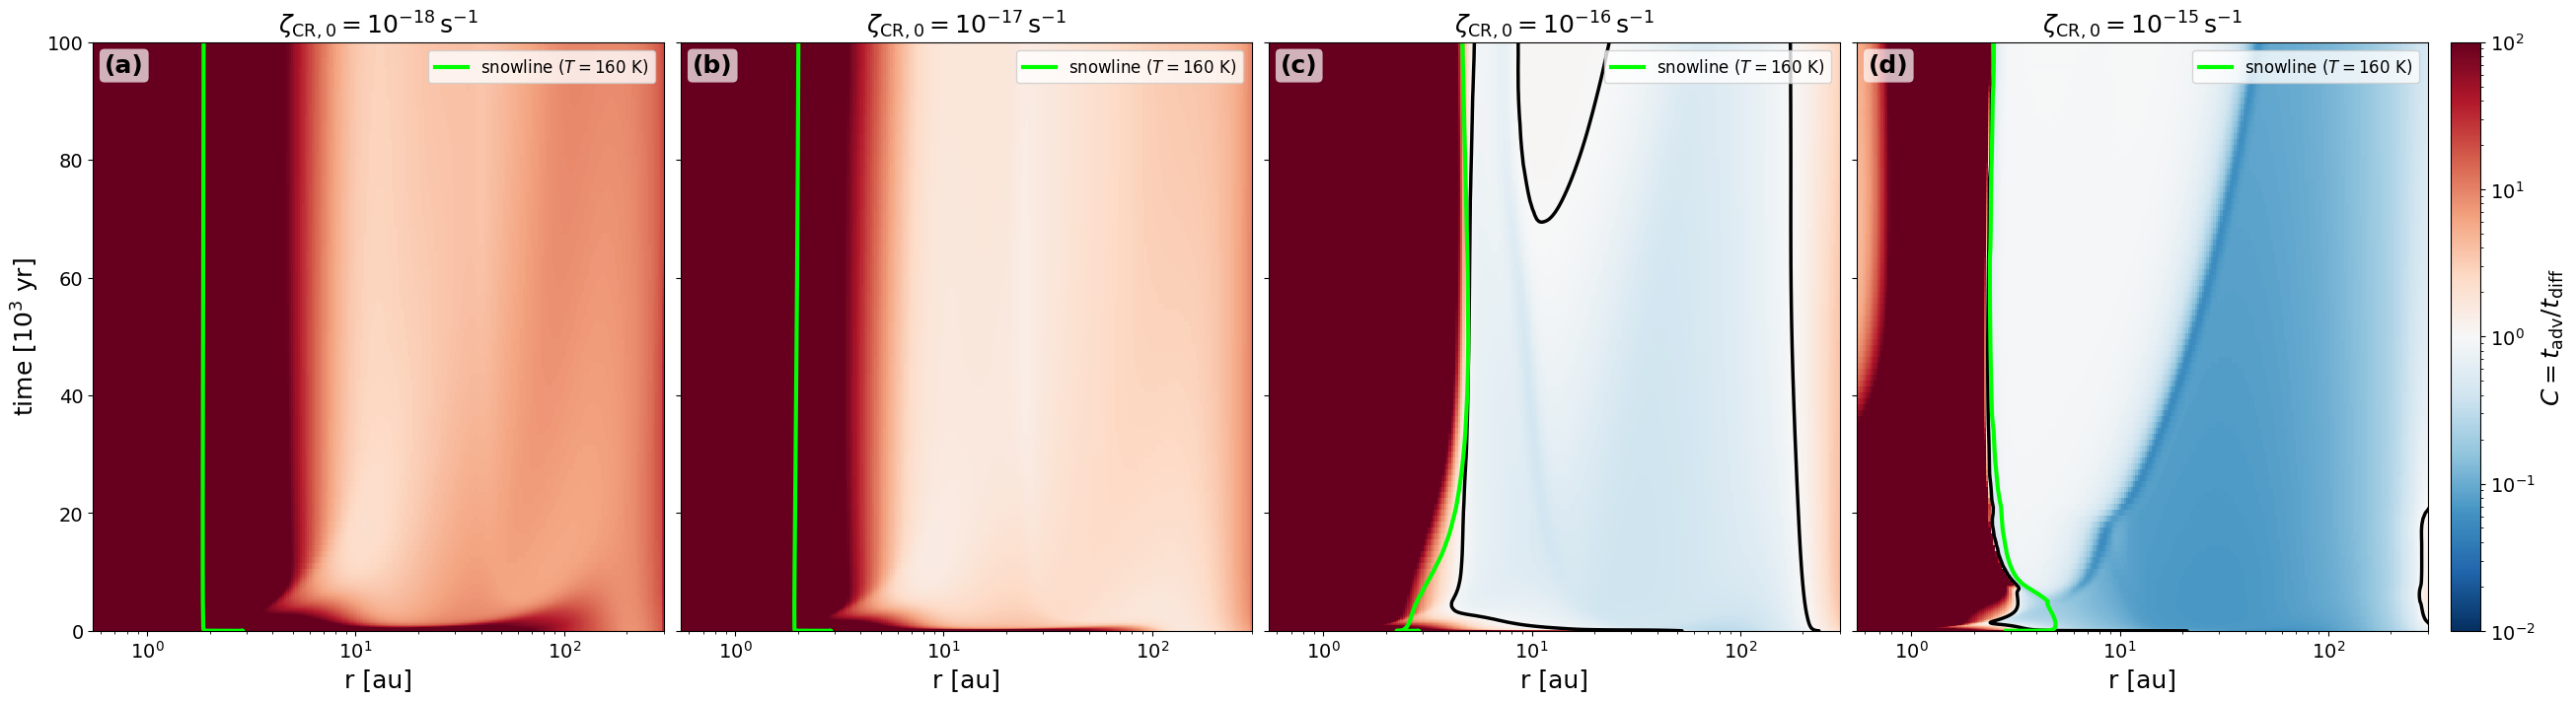

In [12]:
# ======================================================
# 磁場の移流/拡散タイムスケール比 C = t_adv/t_diff の (r,t) 時空図の run 間比較 (1xN ミニマップ) + スノーライン(T=160K)
# analysis_spacetime.ipynb の C の時空図 (旧 cell 38) と同じ定義 :
#   t_adv = r/|v_g,r| , t_diff = r^2/eta_tot  ->  C = eta_tot/(r|v_g,r|)
#   eta_tot = min(etaO_R + etaA_R, eta_max) , eta_max は各 run の input から読む
# v_g,r にはなましをかけない
# 黒実線 : C = 1 , 緑線 : スノーライン
# file_gas 列: 0:r_cen 4:vg_r 12:T     file_mag 列: 3:etaO_R 4:etaA_R
# ======================================================

C_range = (1.0e-2, 1.0e2)   # カラーバーの範囲

def read_eta_max(run):
    eta_max = 1.0e20
    with open(run["dir"] + "/input") as f:
        for line in f:
            if line.split("//")[0].split("=")[0].strip() == "eta_max":
                eta_max = float(line.split("//")[0].split("=")[1])
    return eta_max

def C_spacetime(run):
    eta_max = read_eta_max(run)
    years = list_years(run["dir"], 0, path_mag=b_dir(run))
    C_map, r_snow = [], []
    for year in years:
        gas = load_gas(run, year)
        r, T = gas[:, GAS_R], gas[:, TEMP]
        vgr = gas[:, VG_R]
        B = load_B(run, year)
        eta = np.minimum(B[:, ETA_O] + B[:, ETA_A], eta_max)
        with np.errstate(divide="ignore", invalid="ignore"):
            C = eta / (r * np.abs(vgr))
        C_map.append(np.where(np.isfinite(C) & (C > 0.0), C, np.nan))
        r_snow.append(find_snowline(r, T))
    return r / AU, np.array(years) / 1.0e3, np.array(C_map), np.array(r_snow)

fig, axes = plt.subplots(1, len(RUNS), figsize=(6.5 * len(RUNS), 7), sharey=True, layout="constrained")
norm = LogNorm(vmin=C_range[0], vmax=C_range[1])
for ax, run in zip(axes, RUNS):
    r_au, t, C_map, r_snow = C_spacetime(run)
    pc = ax.pcolormesh(r_au, t, C_map, cmap="RdBu_r", norm=norm, shading="nearest", rasterized=True)
    with np.errstate(divide="ignore", invalid="ignore"):
        ax.contour(r_au, t, np.ma.masked_invalid(np.log10(C_map)), levels=[0.0], colors="black", linewidths=2.5)
    ax.plot(r_snow, t, color="lime", lw=3, label=r"snowline ($T = {:.0f}$ K)".format(T_snow))
    ax.set_xscale("log")
    ax.set_xlim(r_min, r_max)
    ax.set_ylim(t_min, t_max)
    ax.set_xlabel("r [au]")
    ax.set_title(run["label"])
    ax.legend(loc="upper right")
axes[0].set_ylabel(r"time [$10^3$ yr]")
cb = fig.colorbar(pc, ax=axes, pad=0.01)
cb.set_label(r"$C = t_{\rm adv}/t_{\rm diff}$")
plt.show()
